In [1]:
# =========================
# IMPORTS MINIMAUX
# =========================
import numpy as np
import cv2
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt
import deepinv as dinv 
import glob, random
import itertools
import matplotlib.pyplot as plt  

In [2]:
# =========================
# DEVICE
# =========================
device = "cuda" if torch.cuda.is_available() else "cpu"

# =========================
# MODELE
# =========================
denoiser = dinv.models.GSDRUNet(device=device, pretrained='download')
data_fid = dinv.optim.data_fidelity.L2()


# =========================
# OPERATEUR DE FLOU 
# =========================

def gaussian_kernel(size, sigma, channels):
    ax = torch.arange(size).float() - size // 2
    xx, yy = torch.meshgrid(ax, ax, indexing='ij')
    
    kernel = torch.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / kernel.sum()

    # Format correct : (1, C, H, W)
    kernel = kernel.view(1, 1, size, size)
    kernel = kernel.repeat(1, channels, 1, 1)

    return kernel

# création du noyau
# kernel = gaussian_kernel(size=9, sigma=2, channels=3).to(device)

kernel = gaussian_kernel(size=25, sigma=1.6, channels=3).to(device)

physics = dinv.physics.Blur(
    filter=kernel,
    padding='circular', # réduit souvent les artefacts par rapport à 'circular'
    device=device
)

#
def Prox_tau_f(z, y, tau):
    B, C, H, W = z.shape

    # récupérer le noyau (1,C,k,k)
    K = physics.filter

    # créer H avec bonne taille
    H_fft = torch.zeros((B, C, H, W), dtype=torch.complex64, device=z.device) # dtype=torch.complex64

    for c in range(C):
        k = K[0, c]

        # padding au centre (IMPORTANT)
        pad = torch.zeros((H, W), device=z.device)
        kh, kw = k.shape
        pad[:kh, :kw] = k

        # shift pour aligner convolution circulaire
        pad = torch.roll(pad, shifts=(-kh//2, -kw//2), dims=(0,1))

        H_fft[:, c] = torch.fft.fft2(pad)

    H_conj = torch.conj(H_fft)

    Z = torch.fft.fft2(z)
    Y = torch.fft.fft2(y)

    numerator = tau * H_conj * Y + Z
    denominator = 1 + tau * (H_conj * H_fft)

    X = numerator / denominator

    return torch.fft.ifft2(X).real

def D_sigma(x, sigma):
    return denoiser.forward(x, sigma)

def F(x, y, lamda, sigma):
    return 0.5 * torch.norm(physics(x) - y) ** 2 + lamda * denoiser.potential(x, sigma)

def psnr(x_true, x_hat):
    mse = torch.mean((x_true - x_hat) ** 2)
    if mse == 0:
        return float('inf')
    return 10 * torch.log10(1.0 / mse)

# =========================
# PnP ALGORITHM
# =========================
def PnP_with_residus(y, z0, lamda, sigma, epsilon, tau0, K, eta, gamma, x_true=None):
    k = 0
    tau = tau0 / eta
    xk = Prox_tau_f(z0, y, tau)
    x0 = xk.clone()
    delta = float("inf")

    residuals = []
    psnr_values = []

    while k < K and delta > epsilon:
        zk = lamda * tau * D_sigma(xk, sigma) + (1 - lamda * tau) * xk
        xk1 = Prox_tau_f(zk, y, tau)
        
        # 🔹 CLAMP avant tout calcul de métrique
        xk1_clamped = torch.clamp(xk1, 0., 1.)
        
        diff = F(xk, y, lamda, sigma) - F(xk1, y, lamda, sigma)
        residual = torch.norm(xk1 - xk).item()
        residuals.append(residual)

        # 🔹 PSNR calculé sur la version clampée
        if x_true is not None:
            val = psnr(x_true, xk1_clamped).item()
            psnr_values.append(val)

        # Update tau
        if diff < ((gamma / tau) * torch.norm(xk - xk1) ** 2):
            tau = eta * tau
        else:
            delta = diff / (F(x0, y, lamda, sigma) + 1e-8)

        xk = xk1
        k += 1

    # 🔹 Étape finale IDENTIQUE à une itération normale
    zk_final = lamda * tau * D_sigma(xk, sigma) + (1 - lamda * tau) * xk
    x_hat = Prox_tau_f(zk_final, y, tau)
    x_hat = torch.clamp(x_hat, 0., 1.)  # Clamp final

    # 🔹 Ajouter le PSNR final comme un NOUVEAU point (pas un remplacement)
    if x_true is not None:
        final_psnr = psnr(x_true, x_hat).item()
        psnr_values.append(final_psnr)  # ← Append, pas overwrite !

    return x_hat, residuals, psnr_values
################ 

def PnP(y, z0, lamda, sigma, epsilon, tau0, K, eta, gamma):

    k = 0
    tau = tau0 / eta
    xk = Prox_tau_f(z0, y, tau)
    x0 = xk.clone()

    delta = float("inf")

    while k < K and delta > epsilon:

        # denoiser step
        zk = lamda * tau * D_sigma(xk, sigma) + (1 - lamda * tau) * xk

        # prox step 
        xk1 = Prox_tau_f(zk, y, tau)

        # energy check
        diff = F(xk, y, lamda, sigma) - F(xk1, y, lamda, sigma)

        if diff < (gamma / tau) * torch.norm(xk - xk1) ** 2:
            tau = eta * tau
        else:
            delta = diff / (F(x0, y, lamda, sigma) + 1e-8)

        xk = xk1
        k += 1

    x_hat = lamda * tau * D_sigma(xk, sigma) + (1 - lamda * tau) * xk
    
    return torch.clamp(x_hat, 0, 1)   

# DEBLURRING

## Fonction d'affichage

In [3]:
def show(x_true, y, x_restored):

    # calcul PSNR
    psnr_val = psnr(x_true, x_restored).item()

    psnr_degraded = psnr(x_true, y).item() # image dégradé

    fig, ax = plt.subplots(1,3, figsize=(14,4))

    imgs = [x_true, y, x_restored]

    titles = [
        "Originale",
        f"Dégradée\nPSNR = {psnr_degraded:.2f} dB",  
        f"Restaurée\nPSNR = {psnr_val:.2f} dB"
    ]

    for i in range(3):

        img = imgs[i].squeeze().permute(1,2,0).detach().cpu().numpy()
        img = img.clip(0,1)

        ax[i].imshow(img)
        ax[i].set_title(titles[i], fontsize=12)
        ax[i].axis("off")

    plt.tight_layout()
    plt.show()


def zoom_cv2(img_tensor, y1, y2, x1, x2, scale=32):
    img = img_tensor.detach().squeeze().permute(1,2,0).cpu().numpy()

    crop = (img[y1:y2, x1:x2] * 255).astype("uint8")

    zoomed = cv2.resize(
        crop,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_NEAREST
    )

    return zoomed / 255.0

def show_with_zoom(x_true,y,x_restored):

    psnr_degraded = psnr(x_true, y).item()
    psnr_restored = psnr(x_true, x_restored).item()

    fig, ax = plt.subplots(1,3,figsize=(15,5))

    imgs=[x_true,y,x_restored]
    titles=["Original",
           f"Dégradée\nPSNR = {psnr_degraded:.2f} dB",
           f"Restaurée\nPSNR = {psnr_restored:.2f} dB"
           ]
    y1, y2, x1, x2 = 160, 190, 270, 300
    
    for i in range(3):

        img=imgs[i].squeeze().permute(1,2,0).detach().cpu().numpy()
        img=img.clip(0,1)

        ax[i].imshow(img, interpolation='none')
        ax[i].set_title(titles[i])
        ax[i].axis("off")

        axins=ax[i].inset_axes([0.0,0.0,0.40,0.40])

        zoom = zoom_cv2(imgs[i], y1, y2, x1, x2, scale=8)
        axins.imshow(zoom)
        
        axins.set_xticks([])
        axins.set_yticks([])

        for spine in axins.spines.values():
            spine.set_edgecolor('red')
            spine.set_linewidth(2)

        ax[i].add_patch(
            plt.Rectangle(
                (x1,y1),
                x2-x1,
                y2-y1,
                edgecolor='red',
                facecolor='none'
            )
        )

    plt.tight_layout()
    plt.show() 

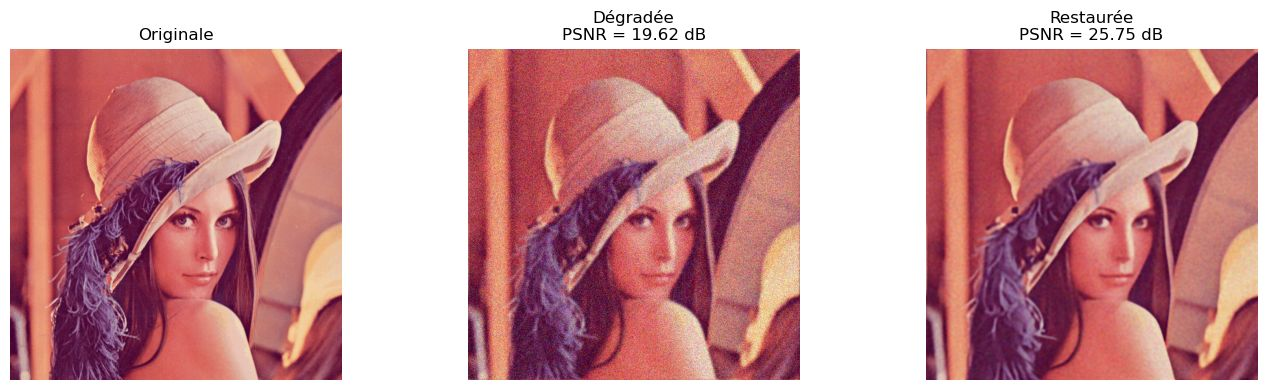

In [4]:
x_true = T.ToTensor()(Image.open("img_009_SRF_2_HR.png").convert("RGB")).unsqueeze(0).to(device)

nu = 0.1  # valeur papier recommandée 
#nu = 0.03
y = physics(x_true)
y = y + nu * torch.randn_like(y)
y = torch.clamp(y, 0, 1)

z0 = y.clone()

x_restored = PnP(
           y=y,
           z0=z0,
           lamda=0.6, #0.075,
           sigma=1.5 * nu,
           epsilon=1e-5,
           tau0=0.99,
           K=100,
           eta=0.95,
           gamma=0.01
        )

show(x_true, y, x_restored)  

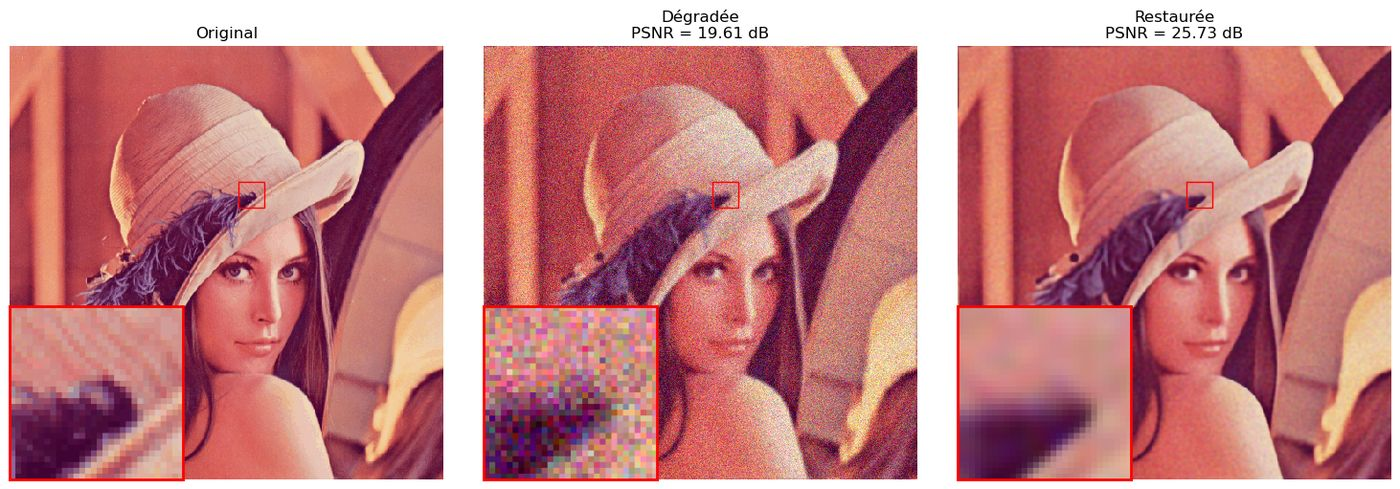

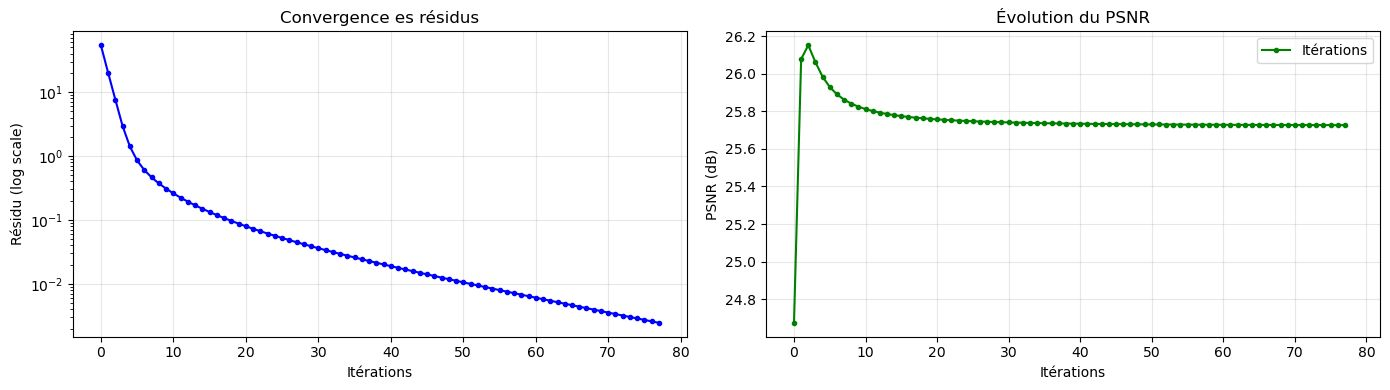

In [5]:
x_true = T.ToTensor()(Image.open("img_009_SRF_2_HR.png").convert("RGB")).unsqueeze(0).to(device)
# nu = 0.05
nu = 0.1 # ajuste le bruit qu'on ajoute dans l'image
y = physics(x_true) + nu * torch.randn_like(x_true) # ajouter du bruit gaussien  
y = torch.clamp(y, 0, 1)  

z0 = y.clone()

x_restored, residuals, psnr_values = PnP_with_residus(
    y=y,
    z0=z0,
    lamda=0.6,
    sigma=1.5*nu,
    epsilon=1e-6,
    tau0=1.0,
    K=100,
    eta=0.95,
    gamma=0.01,
    x_true=x_true
)

x_restored = torch.clamp(x_restored, 0, 1) 

show_with_zoom(x_true, y, x_restored)  

################

# Tracé
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Courbe 1 : Résidu (log)
ax1.semilogy(residuals, 'b-o', markersize=3)
ax1.set_xlabel('Itérations')
ax1.set_ylabel('Résidu (log scale)')
ax1.set_title('Convergence es résidus')
ax1.grid(True, alpha=0.3)

# Courbe 2 : PSNR (avec le point final bien visible)
ax2.plot(psnr_values[:-1], 'g-o', label='Itérations', markersize=3)  # K points
ax2.plot([len(psnr_values)-1], [psnr_values[-1]])  # Point final
ax2.set_xlabel('Itérations')
ax2.set_ylabel('PSNR (dB)')
ax2.set_title('Évolution du PSNR')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# test sur plusieurs images 

/tmp/ipykernel_2996243/808456957.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


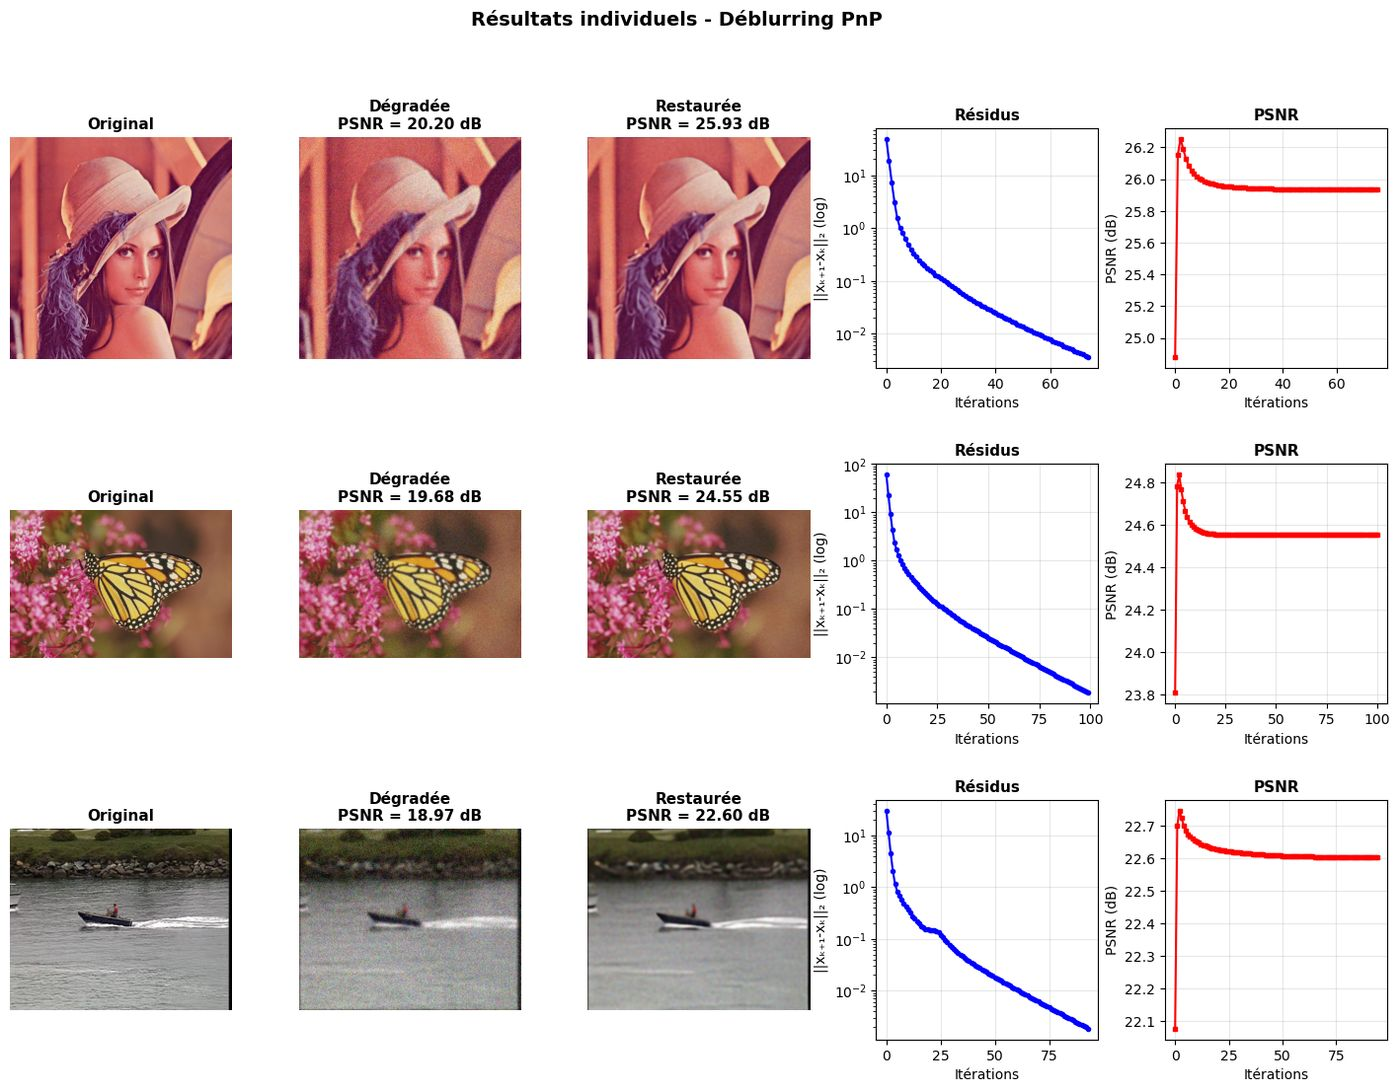

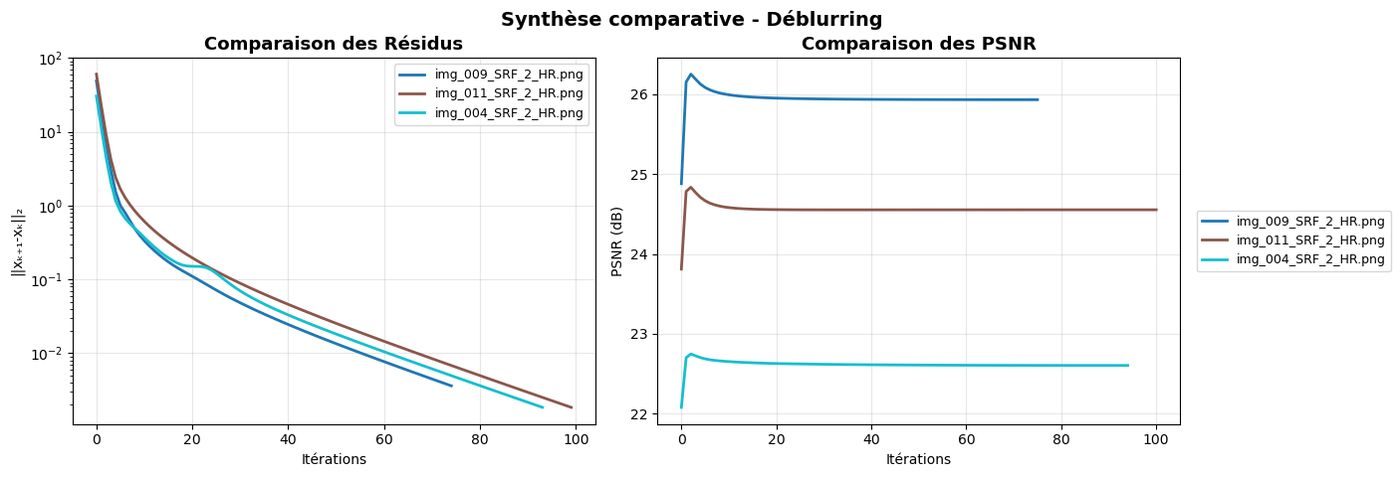

In [7]:
image_paths = [
    "femme.png",
    "papillon2.png",
    "paysage.png"
]

all_residuals = []
all_psnrs = []
all_titles = []
all_results = []

# Fonction utilitaire (définie UNE FOIS)
def to_img(t):
    return np.transpose(torch.clamp(t, 0, 1)[0].cpu().numpy(), (1, 2, 0))

# =========================
# TRAITEMENT PAR IMAGE (DEBLURRING)
# =========================
with torch.no_grad():
    for path in image_paths:   
        # 1. Chargement
        x_true = T.ToTensor()(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
        _, channels, H, W = x_true.shape

        # 2. Mise à jour du noyau de flou (adapté à la taille de l'image)
        kernel = gaussian_kernel(size=25, sigma=2, channels=3).to(device)
        physics = dinv.physics.Blur(
            filter=kernel,
            padding='circular',
            device=device
        )

        # 3. Dégradation : flou + bruit gaussien
        nu = 0.09
        y = physics(x_true) + nu * torch.randn_like(x_true)
        y = torch.clamp(y, 0, 1) 
        z0 = y.clone()  # Initialisation simple pour le déblurring

        # 4. Reconstruction AVEC tracking des métriques
        #  Utiliser PnP_with_residus (et non PnP) pour obtenir residuals/psnr_history
        x_rec, residual_history, psnr_history = PnP_with_residus(
            y=y,
            z0=z0,
            lamda=0.6,
            sigma=1.5 * nu,
            epsilon=1e-6,
            tau0=0.99,
            K=100,
            eta=0.95,
            gamma=0.01,
            x_true=x_true  # ← Essentiel pour le calcul du PSNR à chaque itération
        )
        
        # 5. Stockage des résultats
        all_residuals.append(residual_history)
        all_psnrs.append(psnr_history)
        all_titles.append(path.split("/")[-1])
        all_results.append((x_true, y, x_rec))

# =========================
# FIGURE 1 : RÉSULTATS INDIVIDUELS PAR IMAGE
# =========================
n_imgs = len(image_paths)
fig = plt.figure(figsize=(18, 4 * n_imgs))
gs = fig.add_gridspec(n_imgs, 5, hspace=0.4, wspace=0.3)

for i, (x_true, y, x_rec) in enumerate(all_results):
    ax1 = fig.add_subplot(gs[i, 0])
    ax2 = fig.add_subplot(gs[i, 1])
    ax3 = fig.add_subplot(gs[i, 2])
    ax4 = fig.add_subplot(gs[i, 3])
    ax5 = fig.add_subplot(gs[i, 4])

    # Images
    ax1.imshow(to_img(x_true))
    ax1.set_title("Original", fontsize=11, fontweight='bold')
    ax1.axis("off")

    ax2.imshow(to_img(y))
    psnr_degraded = psnr(x_true, y).item()  # ← Calcul du PSNR dégradé
    ax2.set_title(f"Dégradée\nPSNR = {psnr_degraded:.2f} dB", fontsize=11, fontweight='bold')  
    ax2.axis("off")

    ax3.imshow(to_img(x_rec))
    psnr_final = psnr(x_true, x_rec).item()
    ax3.set_title(f"Restaurée\nPSNR = {psnr_final:.2f} dB", fontsize=11, fontweight='bold')
    ax3.axis("off")

    # Courbe des résidus (échelle log)
    ax4.semilogy(all_residuals[i], 'b-o', linewidth=1.5, markersize=3)
    ax4.set_title("Résidus", fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    ax4.set_xlabel("Itérations")
    ax4.set_ylabel("||xₖ₊₁-xₖ||₂ (log)")

    # Courbe du PSNR
    ax5.plot(all_psnrs[i], 'r-s', linewidth=1.5, markersize=3)
    ax5.set_title("PSNR", fontsize=11, fontweight='bold')
    ax5.grid(True, alpha=0.3)
    ax5.set_xlabel("Itérations")
    ax5.set_ylabel("PSNR (dB)")

fig.suptitle("Résultats individuels - Déblurring PnP", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# =========================
# FIGURE 2 : SYNTHÈSE COMPARATIVE
# =========================
# =========================
# FIGURE 2 : SYNTHÈSE COMPARATIVE
# =========================
fig2, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.tab10(np.linspace(0, 1, n_imgs))
for i in range(n_imgs):
    axes[0].plot(all_residuals[i], label=all_titles[i], color=colors[i], linewidth=2)
    axes[1].plot(all_psnrs[i], label=all_titles[i], color=colors[i], linewidth=2)

# 🔹 Axe Résidus
axes[0].set_title("Comparaison des Résidus", fontsize=13, fontweight='bold')
axes[0].set_yscale("log")
axes[0].legend(fontsize=9, frameon=True, loc='upper right')  # ← Position fixe
axes[0].grid(True, alpha=0.3)
axes[0].set_xlabel("Itérations")
axes[0].set_ylabel("||xₖ₊₁-xₖ||₂")

# 🔹 Axe PSNR : légende à l'EXTÉRIEUR
axes[1].set_title("Comparaison des PSNR", fontsize=13, fontweight='bold')
axes[1].legend(
    fontsize=9, 
    frameon=True, 
    loc='center left',      # ← Ancrage de la légende
    bbox_to_anchor=(1.02, 0.5)  # ← Décalage hors des axes (x=1.02 = juste à droite)
)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel("Itérations")
axes[1].set_ylabel("PSNR (dB)")

fig2.suptitle("Synthèse comparative - Déblurring", fontsize=14, fontweight='bold', y=0.95)

# 🔹 Ajustement des marges pour laisser de la place à la légende externe
plt.tight_layout()
plt.subplots_adjust(right=0.85)  # ← Réduit la largeur des plots pour libérer l'espace droit

plt.show()

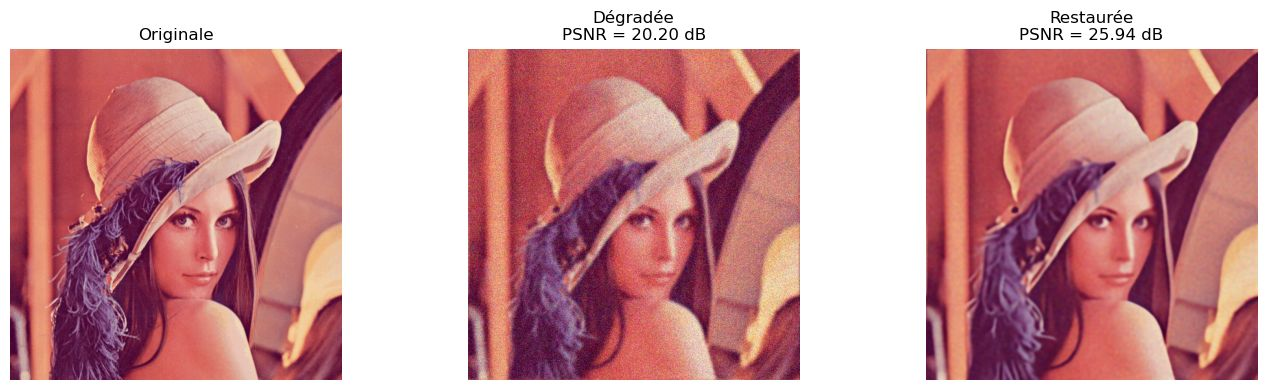

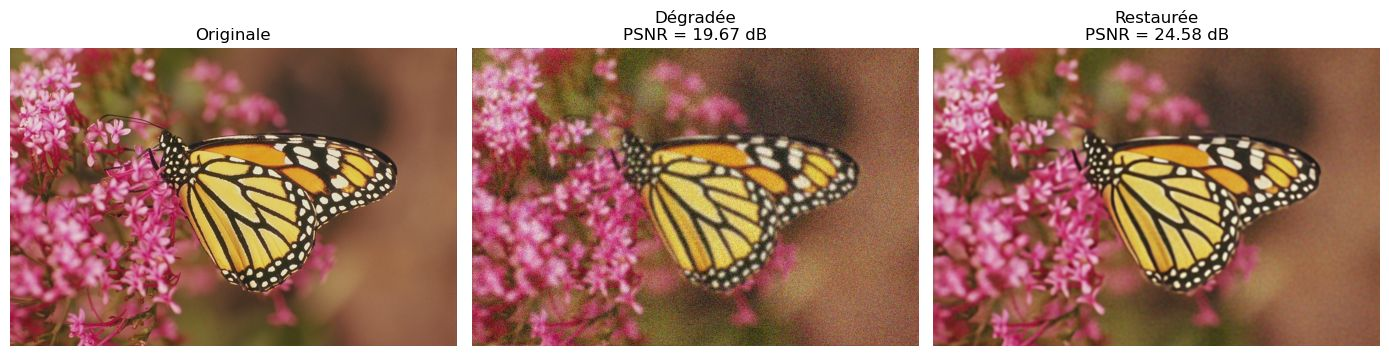

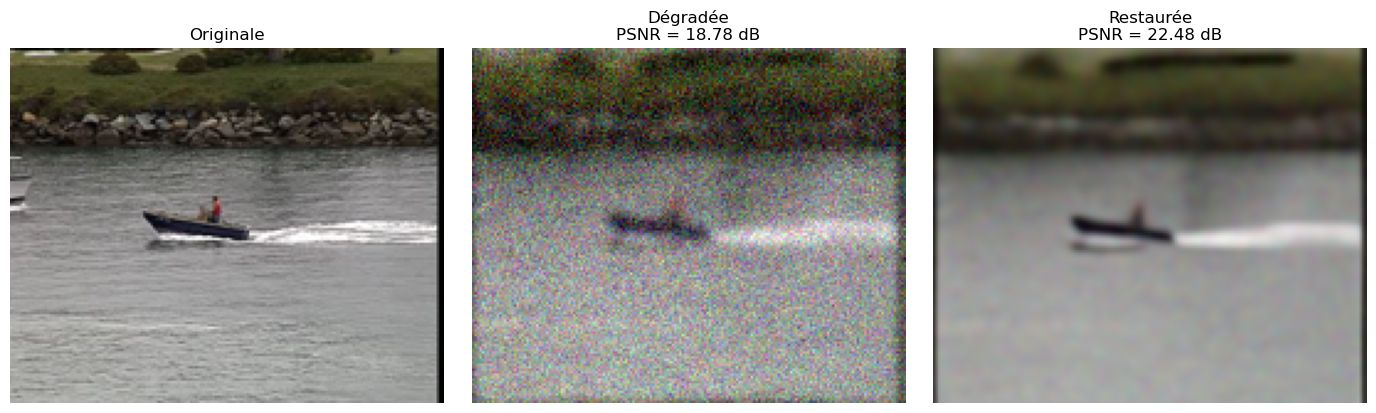

In [8]:
image_paths = [
    "femme.png",
    "papillon.png",
    "paysage.png"
] 

psnr_list = []

with torch.no_grad():
    for path in image_paths:
        # 1. Charger l'image
        x_true = T.ToTensor()(Image.open(path).convert("RGB")).unsqueeze(0).to(device) # .resize(taille_fixe)
        _, channels, H, W = x_true.shape

        # 2. METTRE À JOUR LA VARIABLE GLOBALE PHYSICS
        # On écrase l'ancienne variable pour que PnP() utilise la bonne taille
        kernel = gaussian_kernel(size=25, sigma=2, channels=3).to(device)
        
        physics = dinv.physics.Blur(
            filter=kernel,
            padding='circular',
            device=device
        )

        # 3. Dégradation
        nu = 0.09
        y = physics(x_true) + nu * torch.randn_like(x_true)
        y = torch.clamp(y, 0, 1) 
        z0 = y.clone()

        # 4. Reconstruction (Appel sans l'argument physics)
        x_rec = PnP(
           y=y,
           z0=z0,
           lamda=0.6, #0.075,
           sigma=1.5 * nu,
           epsilon=1e-6,
           tau0=0.99,
           K=50,
           eta=0.95,
           gamma=0.01
        )
        
        # PSNR et Affichage
        val = psnr(x_true, x_rec).item() 
        psnr_list.append(val)
        show(x_true, y, x_rec)  

## test sur differentes valeurs de lambda

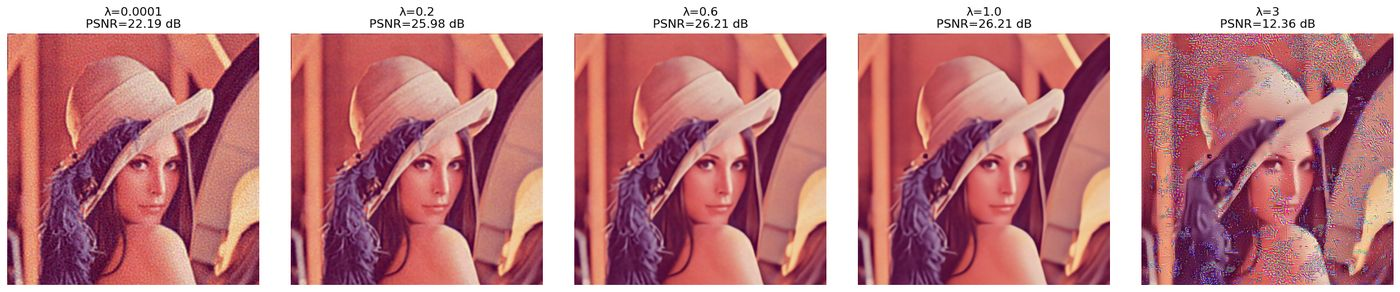

In [9]:
# ↓ sigma → moins de lissage → + détails
# ↑ lambda → le prior agit plus → + netteté

lambdas = [0.0001, 0.2, 0.6, 1.0, 3] 

nu = 0.05

#x_true = T.ToTensor()(Image.open("Set14/image_SRF_2/img_009_SRF_2_HR.png").resize((256,256))).unsqueeze(0).to(device)
x_true = T.ToTensor()(Image.open("img_009_SRF_2_HR.png").convert("RGB")).unsqueeze(0).to(device)

C, H, W = x_true.shape[1:]  # Récupère les dimensions réelles


kernel = gaussian_kernel(size=25, sigma=2, channels=C).to(device)
physics = dinv.physics.Blur(
    filter=kernel,
    padding='circular',
    device=device
)

# Dégradation
y = physics(x_true) + nu*torch.randn_like(x_true)
y = torch.clamp(y,0,1)

z0 = y.clone() 

restored_images = []
psnrs = []

with torch.no_grad():

    for lamda in lambdas:

        x_restored = PnP(
            y=y,
            z0=z0,
            lamda=lamda,
            sigma=1.4*nu,
            epsilon=1e-6,
            tau0=0.99,
            K=50,
            eta=0.95,
            gamma=0.01
        )

        restored_images.append(x_restored)

        psnr_val = psnr(x_true, x_restored).item()
        psnrs.append(psnr_val)


# =========================
# DISPLAY GRID
# =========================

n = len(lambdas)
fig, axes = plt.subplots(1,n, figsize=(4*n,4))

for i in range(n):

    img = restored_images[i].squeeze().permute(1,2,0).cpu().numpy()
    img = img.clip(0,1)

    axes[i].imshow(img)

    axes[i].set_title(
        f"λ={lambdas[i]}\nPSNR={psnrs[i]:.2f} dB",
        fontsize=12
    )

    axes[i].axis("off")

plt.tight_layout() 
plt.show()     

# Test sur différentes valeurs de sigma 

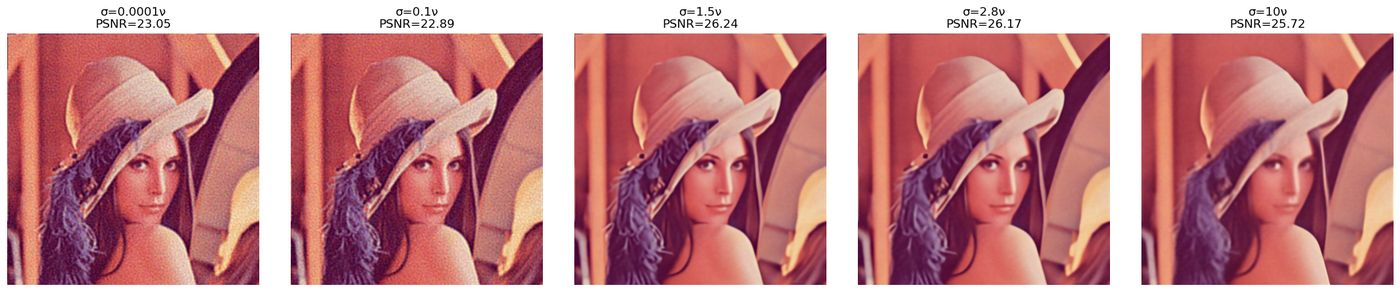

In [10]:
# =========================
# TEST SUR DIFFERENTS SIGMA
# =========================

# sigma_factors = [0.8, 1.8, 2, 3.5]
sigma_factors = [0.0001, 0.1, 1.5, 2.8, 10] 

nu = 0.05
lamda = 0.6

x_true = T.ToTensor()(Image.open("img_009_SRF_2_HR.png").convert("RGB")).unsqueeze(0).to(device)


C, H, W = x_true.shape[1:]  # Récupère les dimensions réelles


kernel = gaussian_kernel(size=25, sigma=2, channels=C).to(device)
physics = dinv.physics.Blur(
    filter=kernel,
    padding='circular',
    device=device
)

# image dégradée
y = physics(x_true) + nu * torch.randn_like(x_true)
y = torch.clamp(y,0,1)

z0 = y.clone()

restored_images = []
psnrs = []

with torch.no_grad():

    for fac in sigma_factors:

        sigma_test = fac * nu

        x_restored = PnP(
            y=y,
            z0=z0,
            lamda=lamda,
            sigma=sigma_test,
            epsilon=1e-6,
            tau0=0.99,
            K=30,
            eta=0.95,
            gamma=0.01
        )

        restored_images.append(x_restored)

        p = psnr(x_true, x_restored).item()
        psnrs.append(p)


# =========================
# AFFICHAGE
# =========================

n = len(sigma_factors)

fig, axes = plt.subplots(1,n, figsize=(4*n,4))

for i in range(n):

    img = restored_images[i].squeeze().permute(1,2,0).cpu().numpy()
    img = img.clip(0,1)

    axes[i].imshow(img)
    axes[i].set_title(
        f"σ={sigma_factors[i]}ν\nPSNR={psnrs[i]:.2f}"
    )
    axes[i].axis("off")
 
plt.tight_layout() 
plt.show()          

# Recherche automoatique des meilleurs paramètres : lambda / sigma

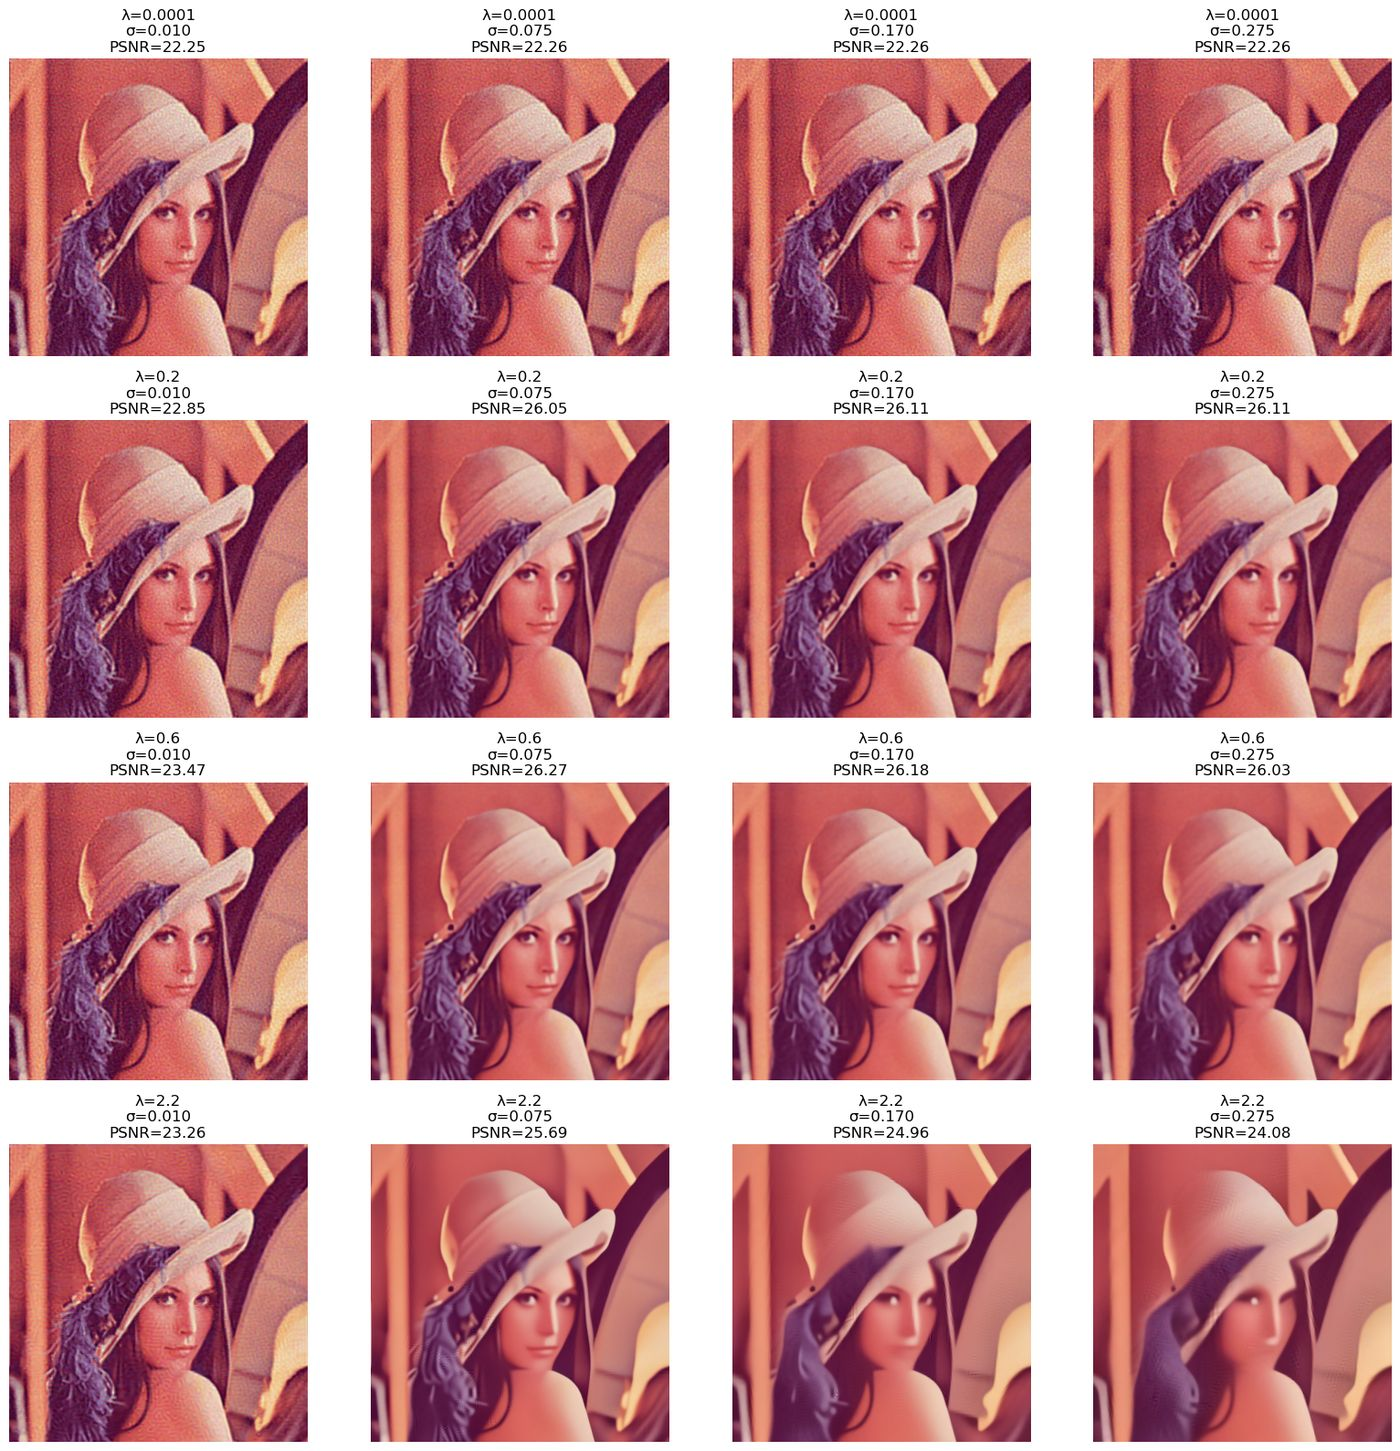


Meilleur réglage trouvé:
lambda = 0.6
sigma  = 0.0750
PSNR   = 26.27 dB


In [11]:
nu=0.05
lambdas = [0.0001, 0.2, 0.6, 2.2] # [0.08, 0.2, 0.04, 0.6]
sigmas  = [0.2*nu, 1.5*nu, 3.4*nu, 5.5*nu]  # [0.8*nu, 1.0*nu, 1.2*nu, 1.5*nu] # [0.8, 1.8, 2, 3.5] 
 
# image
x_true = T.ToTensor()(Image.open("img_009_SRF_2_HR.png").convert("RGB")).unsqueeze(0).to(device)


C, H, W = x_true.shape[1:]  # Récupère les dimensions réelles

kernel = gaussian_kernel(size=25, sigma=2, channels=C).to(device)
physics = dinv.physics.Blur(
    filter=kernel,
    padding='circular',
    device=device
)

# dégradation
nu = 0.05
y = physics(x_true) + nu*torch.randn_like(x_true)
y = torch.clamp(y,0,1)

z0 = y.clone()

results = []
images = []

with torch.no_grad():

    for lamda, sigma_test in itertools.product(lambdas,sigmas):

        x_restored = PnP(
            y=y,
            z0=z0,
            lamda=lamda,
            sigma=sigma_test,
            epsilon=1e-5,
            tau0=1.0,
            K=40,
            eta=0.95,
            gamma=0.01
        )

        val = psnr(x_true,x_restored).item()

        results.append(
            (lamda,sigma_test,val)
        )

        images.append(x_restored)


# =========================
# Affichage grille
# =========================

rows=len(lambdas)
cols=len(sigmas)

fig,axes=plt.subplots(rows,cols,
                      figsize=(4*cols,4*rows))

k=0
for i in range(rows):
    for j in range(cols):

        img=images[k].squeeze().permute(1,2,0).cpu().numpy()
        img=img.clip(0,1)

        lam,sig,p=results[k]

        axes[i,j].imshow(img)
        axes[i,j].set_title(
            f"λ={lam}\nσ={sig:.3f}\nPSNR={p:.2f}"
        )
        axes[i,j].axis("off")

        k+=1

plt.tight_layout()
plt.show()


# =========================
# meilleur couple
# =========================

best=max(results,key=lambda t:t[2])

print("\nMeilleur réglage trouvé:")
print(f"lambda = {best[0]}")
print(f"sigma  = {best[1]:.4f}")
print(f"PSNR   = {best[2]:.2f} dB")                                

# Inpainting

## Inpaintaing sans bruit

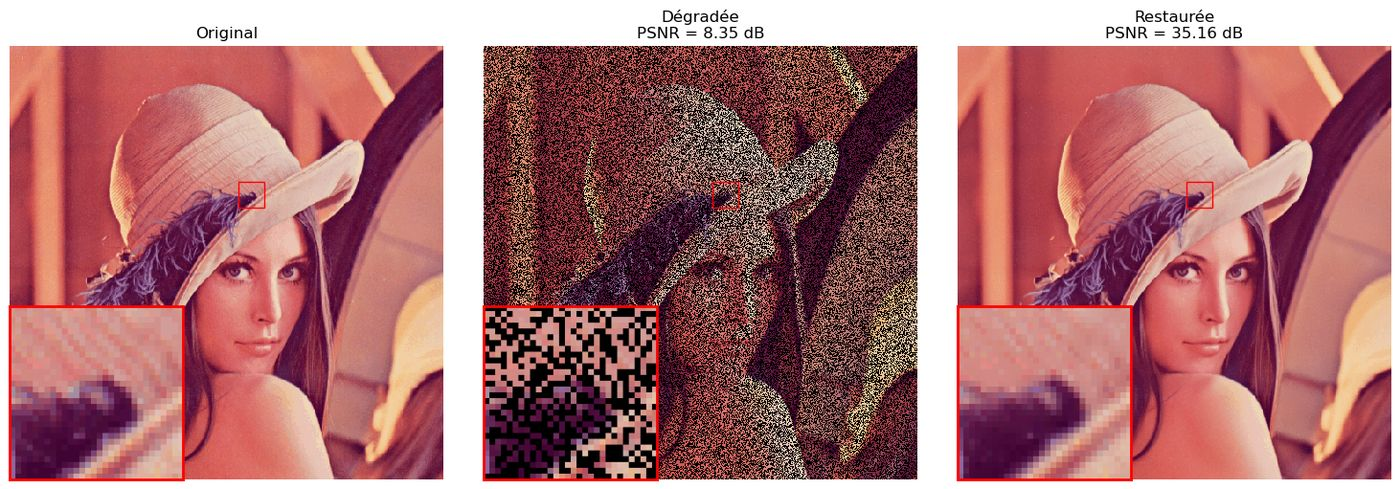

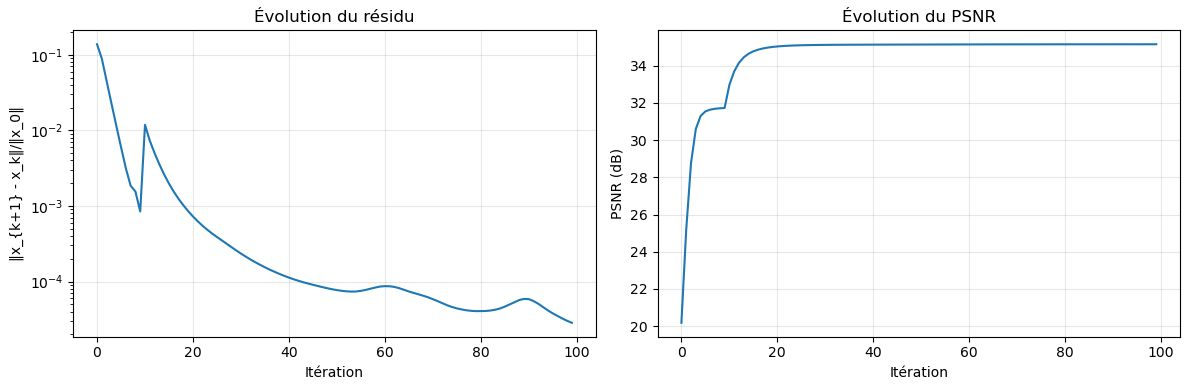

In [12]:
# test  
import torch
import torchvision.transforms as T 
from PIL import Image 
import deepinv as dinv 

# =========================
# IMAGE
# =========================
x_true = T.ToTensor()(Image.open("img_009_SRF_2_HR.png").convert("RGB")).unsqueeze(0).to(device)
 

# =========================
# MASQUE INPAINTING
# =========================
# Shape (1, H, W) ou (C, H, W) suffit, deepinv gère le broadcasting
mask = torch.bernoulli(
    0.5 * torch.ones(1, x_true.shape[2], x_true.shape[3])
).to(device)

# =========================
# PHYSICS
# =========================
physics = dinv.physics.Inpainting(
    mask=mask,
    img_size=x_true.shape[1:],  # (C,H,W)
    device=device
)

def Prox_inpainting(z, y, mask):
    # Forme équivalente et légèrement plus stable numériquement
    return z + mask * (y - z)



# =========================
# PnP GS
# =========================

def PnP_inpainting_GS(y, z0, mask, sigma_main, sigma_warmup, K, n_warmup, D_sigma):

    if hasattr(D_sigma, 'eval'):
        D_sigma.eval()

    xk = z0.clone()
    x0_norm = torch.norm(z0).item() + 1e-8

    #  AJOUTS POUR COURBES
    residual_history = []
    psnr_history = []

    for k in range(K):
        sigma_k = sigma_warmup if k < n_warmup else sigma_main

        with torch.no_grad():
            zk = D_sigma(xk, sigma_k)

        xk1 = Prox_inpainting(zk, y, mask)
        xk1 = torch.clamp(xk1, 0., 1.)

        # =========================
        #  COURBES (AJOUT MINIMAL)
        # =========================
        res = torch.norm(xk1 - xk).item() / x0_norm
        residual_history.append(res)

        psnr_val = psnr(x_true, xk1).item()
        psnr_history.append(psnr_val)

        #if k % 10 == 0:
           # print(f"Iter {k:3d} | residual = {res:.6f} | sigma = {sigma_k:.4f}")

        xk = xk1

    return xk, residual_history, psnr_history

# =========================
# DÉGRADATION & INIT
# =========================
y = physics(x_true)
z0 = torch.where(mask.bool(), y, 0.5)  # Initialisation neutre sur les zones masquées

# ========================= 
# PARAMÈTRES
# ========================= 
sigma_main = 10/255
sigma_warmup = 50/255
K = 100
n_warmup = 10

# =========================
# RESTAURATION
# =========================
#x_restored = PnP_inpainting_GS(y, z0, mask, sigma_main, sigma_warmup, K, n_warmup, D_sigma)

x_restored, residual_history, psnr_history = PnP_inpainting_GS(
    y, z0, mask, sigma_main, sigma_warmup, K, n_warmup, D_sigma
)

# =========================
# ÉVALUATION
# ========================= 

show_with_zoom(x_true, y, x_restored)   


# =========================
# COURBES (résidu + PSNR)
# =========================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Résidus
axes[0].plot(residual_history, linewidth=1.5)
axes[0].set_title("Évolution du résidu")
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("‖x_{k+1} - x_k‖/‖x_0‖") 
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)

# PSNR
axes[1].plot(psnr_history, linewidth=1.5)
axes[1].set_title("Évolution du PSNR")
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("PSNR (dB)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show() 

## test sur pluisieurs images

papillon2.png
femme.png
paysage.png


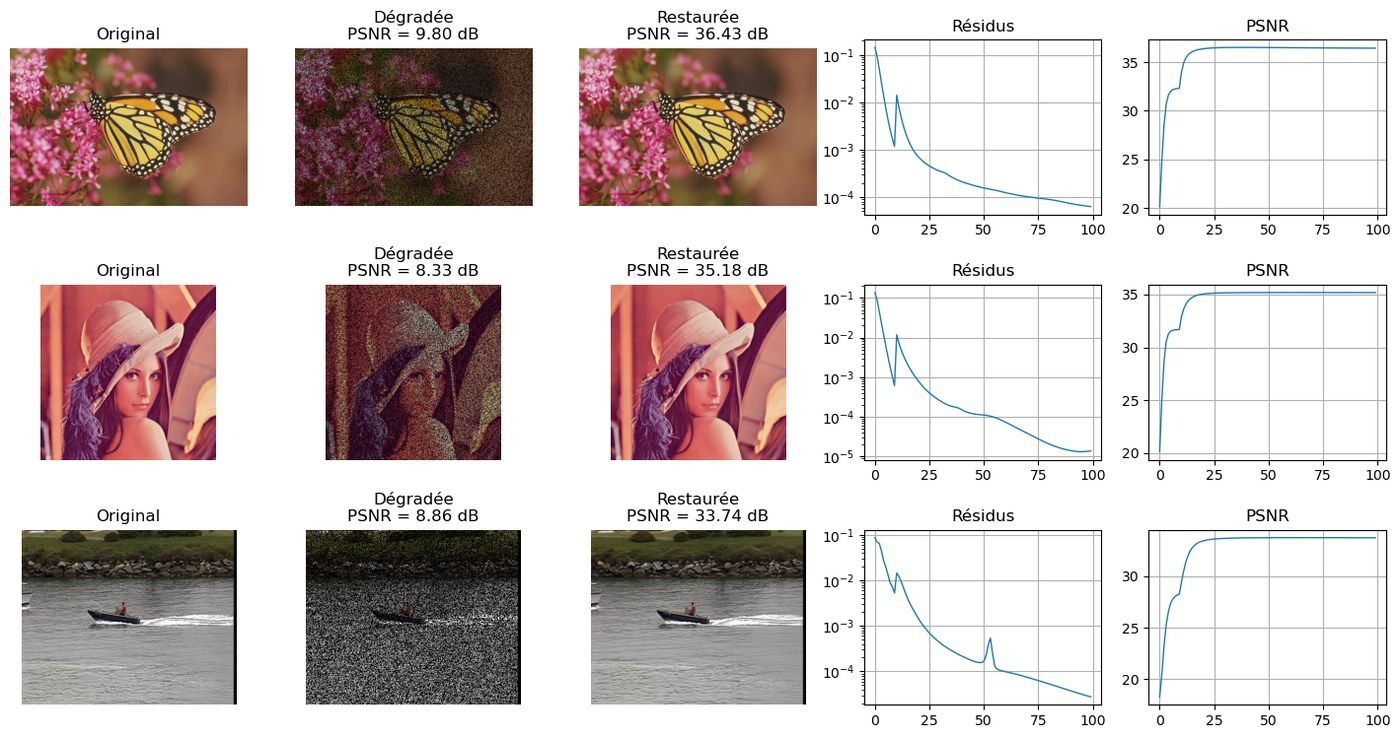

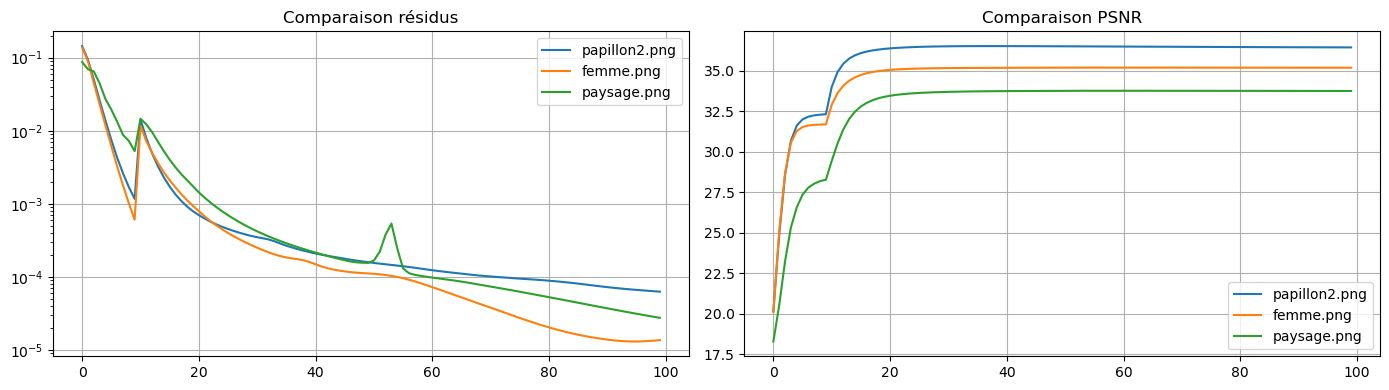

In [23]:
image_paths = [ 
    "papillon2.png",
    "femme.png",
    "paysage.png"
] 
 

all_residuals = []
all_psnrs = []
all_titles = []
all_results = []

for image in image_paths:

    print(image)
    
    # =========================
    # IMAGE
    # =========================
    x_true = T.ToTensor()(Image.open(image).convert("RGB")).unsqueeze(0).to(device)

    # =========================
    # MASQUE
    # =========================
    mask = torch.bernoulli( 0.5 * torch.ones(1, x_true.shape[2], x_true.shape[3])).to(device)

    physics = dinv.physics.Inpainting(
        mask=mask,
        img_size=x_true.shape[1:],
        device=device
    )

    # =========================
    # DEGRADED
    # =========================
    y = physics(x_true)
    z0 = torch.where(mask.bool(), y, 0.5)

    # =========================
    # RESTAURATION
    # =========================
    x_restored, residual_history, psnr_history = PnP_inpainting_GS(
        y, z0, mask, sigma_main, sigma_warmup, K, n_warmup, D_sigma
    )

    # show_with_zoom(x_true, y, x_restored) 
    # =========================
    # STOCKAGE
    # =========================
    all_residuals.append(residual_history)
    all_psnrs.append(psnr_history)
    all_titles.append(image.split("/")[-1])
    all_results.append((x_true, y, x_restored))

# =========================
# FIGURE COMPARATIVE IMAGES
# =========================
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(len(image_paths)+1, 5, hspace=0.4)

for i, (x_true, y, x_restored) in enumerate(all_results):

    def to_img(t):
        return np.transpose(
            torch.clamp(t,0,1)[0].cpu().numpy(),
            (1,2,0)
        )

    # =========================
    # PSNR
    # =========================
    psnr_degraded = psnr(x_true, y).item()

    psnr_restored = psnr(x_true, x_restored).item()

    ax1 = fig.add_subplot(gs[i, 0])
    ax2 = fig.add_subplot(gs[i, 1])
    ax3 = fig.add_subplot(gs[i, 2])
    ax4 = fig.add_subplot(gs[i, 3])
    ax5 = fig.add_subplot(gs[i, 4])

    ax1.imshow(to_img(x_true))
    ax1.set_title("Original")
    ax1.axis("off")

    ax2.imshow(to_img(y))
    ax2.set_title(f"Dégradée\nPSNR = {psnr_degraded:.2f} dB")
    ax2.axis("off")

    ax3.imshow(to_img(x_restored))
    ax3.set_title(f"Restaurée\nPSNR = {psnr_restored:.2f} dB")
    ax3.axis("off")

    ax4.plot(all_residuals[i], linewidth=1)
    ax4.set_title("Résidus")
    ax4.set_yscale("log")
    ax4.grid()

    ax5.plot(all_psnrs[i], linewidth=1)
    ax5.set_title("PSNR")
    ax5.grid()

# =========================
# FIGURE COMPARATIVE COURBES
# =========================
fig2, axes = plt.subplots(1, 2, figsize=(14, 4))

for i in range(len(image_paths)):
    axes[0].plot(all_residuals[i], label=all_titles[i])
    axes[1].plot(all_psnrs[i], label=all_titles[i])

axes[0].set_title("Comparaison résidus")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid()

axes[1].set_title("Comparaison PSNR")
axes[1].legend()
axes[1].grid()

plt.tight_layout() 
plt.show()              

## Inpainting avec bruit


PSNR : 26.45 dB


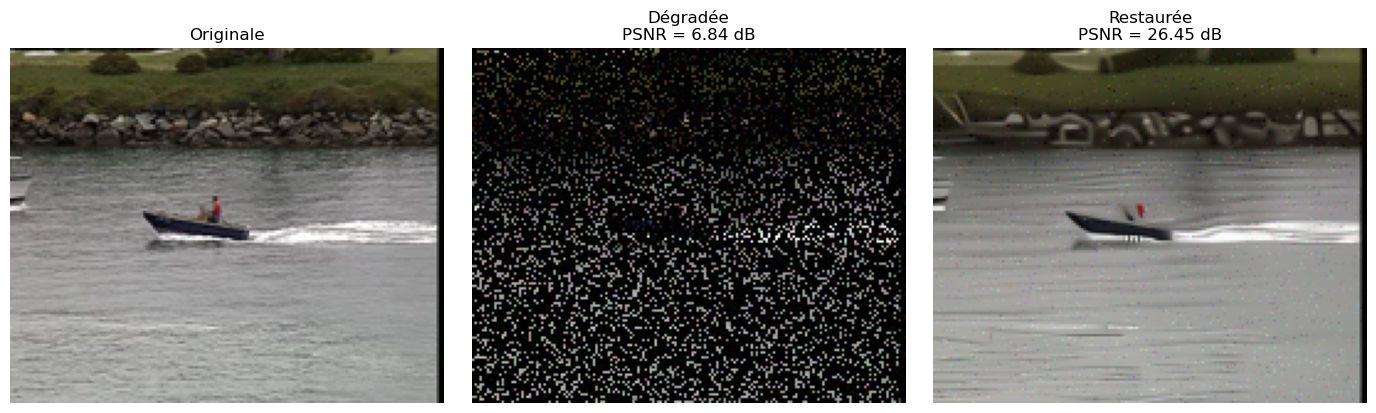

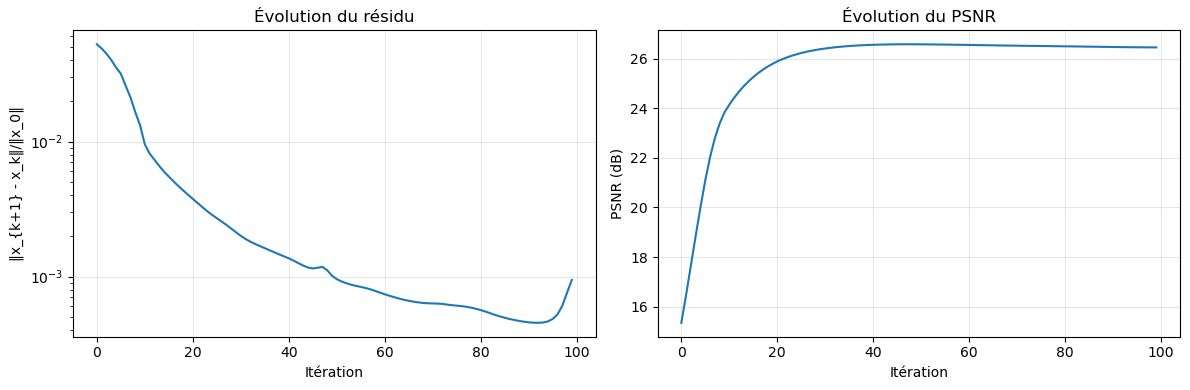

In [14]:
# mask = torch.bernoulli(0.2 * ones)  # 20% des pixels connus, cas plus difficile:  
 
mask = torch.bernoulli(  
    0.2 * torch.ones(1, 1, x_true.shape[2], x_true.shape[3]) 
).to(device)

mask = mask.expand_as(x_true)

# =========================
# PHYSICS (A = mask)
# =========================
physics = dinv.physics.Inpainting(
    mask=mask,
    img_size=x_true.shape[1:],  # (C,H,W)
    device=device
)

# =========================
# DEGRADATION (SANS BRUIT)
# =========================

nu = 0.03
y = physics(x_true)
y = y + nu * torch.randn_like(y)

# =========================
# INITIALISATION (papier)
# =========================
# z0 = y + 0.5 * (1 - mask)*y

# Initialisation neutre (gris moyen) sur les zones masquées
z0 = torch.where(mask.bool(), y, torch.tensor(0.5).to(device))

# =========================
# PARAMETRES PAPIER
# =========================
sigma_main = 10/255       # ≈ 0.039
sigma_warmup = 50/255     # ≈ 0.196
K = 100
n_warmup = 10

# =========================
# RESTAURATION
# =========================

x_restored, residual_history, psnr_history = PnP_inpainting_GS(
        y, z0, mask, sigma_main, sigma_warmup, K, n_warmup, D_sigma
    )


# =========================
# PSNR
# =========================
print(f"\nPSNR : {psnr(x_true, x_restored).item():.2f} dB")

# show(x_true, y, x_restored)   
show(x_true, y, x_restored)

# COURBES (résidu + PSNR)
# =========================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Résidus
axes[0].plot(residual_history, linewidth=1.5)
axes[0].set_title("Évolution du résidu")
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("‖x_{k+1} - x_k‖/‖x_0‖") 
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)

# PSNR
axes[1].plot(psnr_history, linewidth=1.5)
axes[1].set_title("Évolution du PSNR")
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("PSNR (dB)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show() 

# IMR

Itération   0 | résidu = 10.627508 | sigma = 0.19608 | PSNR = 22.71 dB
Itération  20 | résidu = 0.215896 | sigma = 0.01961 | PSNR = 28.64 dB
Itération  40 | résidu = 0.116779 | sigma = 0.01961 | PSNR = 29.62 dB
Itération  60 | résidu = 0.080901 | sigma = 0.01961 | PSNR = 30.16 dB
Itération  80 | résidu = 0.051380 | sigma = 0.01961 | PSNR = 30.44 dB
Itération 100 | résidu = 0.027631 | sigma = 0.01961 | PSNR = 30.59 dB
Itération 120 | résidu = 0.017318 | sigma = 0.01961 | PSNR = 30.69 dB
Itération 140 | résidu = 0.013671 | sigma = 0.01961 | PSNR = 30.76 dB
Itération 160 | résidu = 0.012153 | sigma = 0.01961 | PSNR = 30.82 dB
Itération 180 | résidu = 0.011271 | sigma = 0.01961 | PSNR = 30.87 dB


/tmp/ipykernel_2996243/4255892656.py:160: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure sauvegardée : mri_with_curves.png


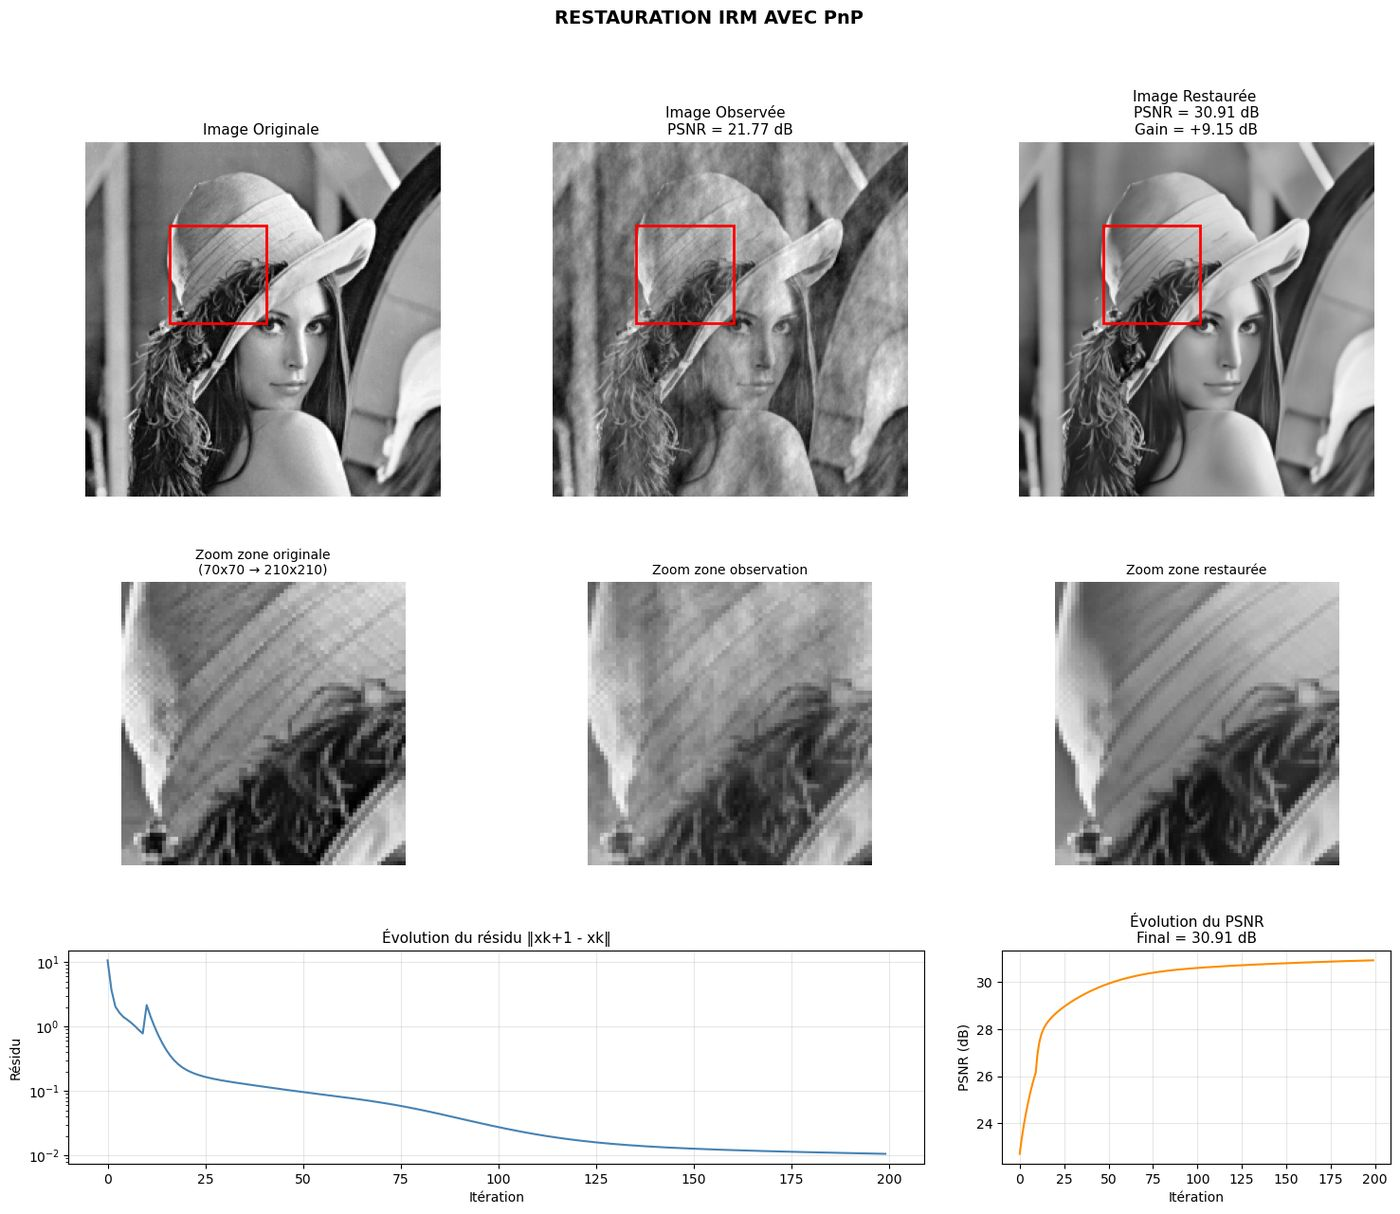

In [44]:
# =========================
# CHARGEMENT & ALIGNEMENT STRICT
# =========================
# 1. Chargement
x_true_gray = T.ToTensor()(Image.open("femme.png").convert("L")).unsqueeze(0).to(device)
x_true = torch.cat([x_true_gray, torch.zeros_like(x_true_gray)], dim=1)  # Format MRI (1, 2, H, W)

target_size = 256
x_true = torch.nn.functional.interpolate(x_true, size=(target_size, target_size), mode='bilinear', align_corners=False)

_, C, H, W = x_true.shape  # H et W valent maintenant 256

# 3. Masque & Physics alignés EXACTEMENT sur x_true
mask = torch.bernoulli(0.7 * torch.ones(H, W)).to(device)
physics = dinv.physics.MRI(
    mask=mask,
    img_size=(H, W),  # deepinf utilise (H, W)
    device=device
)

# 4. Observation
y = physics(x_true)

# =========================
# ALGORITHME PnP IRM AVEC SUIVI PSNR
# =========================
def PnP_MRI_with_history(y, K=200, sigma_main=5/255, sigma_warmup=50/255, n_warmup=10, tau=1.0, x_true=None):
    """
    Version avec historique du résidu et du PSNR
    """
    xk = physics.A_adjoint(y).detach()
    
    residual_history = []
    psnr_history = []
    
    for k in range(K):
        sigma_k = sigma_warmup if k < n_warmup else sigma_main
        
        with torch.no_grad():
            zk = D_sigma(xk, sigma_k)
            xk1 = Prox_tau_f_mri(zk, y, tau)
        
        residual = torch.norm(xk1 - xk).item()
        residual_history.append(residual)
        
        if x_true is not None:
            current_psnr = psnr_mri(x_true, xk1).item()
            psnr_history.append(current_psnr)
        
        if k % 20 == 0:
            if x_true is not None:
                print(f"Itération {k:3d} | résidu = {residual:.6f} | sigma = {sigma_k:.5f} | PSNR = {current_psnr:.2f} dB")
            else:
                print(f"Itération {k:3d} | résidu = {residual:.6f} | sigma = {sigma_k:.5f}")
        
        xk = xk1.detach()
    
    return xk.detach(), residual_history, psnr_history

# =========================
# AFFICHAGE IRM AVEC ZOOM + COURBES
# =========================
def show_mri_with_curves(x_true, y, x_restored, residual_history, psnr_history,
                           zoom_zone=(60, 60, 130, 130), fx=3.0, fy=3.0, save_path=None):
    """
    Affiche les 3 images (Originale, Observation, Restaurée)
    En dessous : les zooms des zones
    Et en bas : courbes d'évolution du résidu et du PSNR
    """
    x1, y1, x2, y2 = zoom_zone
    
    # ========== CONVERSION IRM -> IMAGE ==========
    def mri_to_image(tensor):
        if tensor.dim() == 4:
            mag = torch.sqrt(tensor[0, 0]**2 + tensor[0, 1]**2)
        else:
            mag = torch.sqrt(tensor[0]**2 + tensor[1]**2)
        img = mag.cpu().detach().numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        img = (img * 255).astype(np.uint8)
        return cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    
    # Obtenir les 3 images
    img_true = mri_to_image(x_true)
    observation = physics.A_adjoint(y).detach()
    img_observation = mri_to_image(observation)
    img_restored = mri_to_image(x_restored)
    
    # ========== ZOOM ==========
    zone_true = img_true[y1:y2, x1:x2]
    zone_observation = img_observation[y1:y2, x1:x2]
    zone_restored = img_restored[y1:y2, x1:x2]
    
    zoom_true = cv2.resize(zone_true, None, fx=fx, fy=fy, interpolation=cv2.INTER_NEAREST)
    zoom_observation = cv2.resize(zone_observation, None, fx=fx, fy=fy, interpolation=cv2.INTER_NEAREST)
    zoom_restored = cv2.resize(zone_restored, None, fx=fx, fy=fy, interpolation=cv2.INTER_NEAREST)
    
    # ========== PSNR ==========
    psnr_obs = psnr_mri(x_true, observation).item()
    psnr_rest = psnr_mri(x_true, x_restored).item()
    final_psnr = psnr_history[-1] if psnr_history else psnr_rest
    
    # ========== CONVERSION BGR -> RGB ==========
    img_true_rgb = cv2.cvtColor(img_true, cv2.COLOR_BGR2RGB)
    img_observation_rgb = cv2.cvtColor(img_observation, cv2.COLOR_BGR2RGB)
    img_restored_rgb = cv2.cvtColor(img_restored, cv2.COLOR_BGR2RGB)
    zoom_true_rgb = cv2.cvtColor(zoom_true, cv2.COLOR_BGR2RGB)
    zoom_observation_rgb = cv2.cvtColor(zoom_observation, cv2.COLOR_BGR2RGB)
    zoom_restored_rgb = cv2.cvtColor(zoom_restored, cv2.COLOR_BGR2RGB)
    
    # ========== AFFICHAGE ==========
    fig = plt.figure(figsize=(18, 14))
    gs = fig.add_gridspec(3, 3, height_ratios=[1, 0.8, 0.6], hspace=0.3, wspace=0.2)
    
    # LIGNE 1 : Images complètes
    titles_row1 = [
        f"Image Originale ",
        f"Image Observée  \nPSNR = {psnr_obs:.2f} dB",
        f"Image Restaurée \nPSNR = {psnr_rest:.2f} dB\nGain = +{psnr_rest - psnr_obs:.2f} dB"
    ]
    
    for i, (img, title) in enumerate(zip([img_true_rgb, img_observation_rgb, img_restored_rgb], titles_row1)):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(img, cmap='gray')
        ax.set_title(title, fontsize=11)
        ax.axis('off')
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
    
    # LIGNE 2 : Zooms
    titles_row2 = [
        f"Zoom zone originale\n({zone_true.shape[1]}x{zone_true.shape[0]} → {zoom_true.shape[1]}x{zoom_true.shape[0]})",
        f"Zoom zone observation",
        f"Zoom zone restaurée"
    ]
    
    for i, (img, title) in enumerate(zip([zoom_true_rgb, zoom_observation_rgb, zoom_restored_rgb], titles_row2)):
        ax = fig.add_subplot(gs[1, i])
        ax.imshow(img, cmap='gray')
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    
    # LIGNE 3 : Courbes
    ax_res = fig.add_subplot(gs[2, 0:2])
    ax_res.plot(residual_history, color='steelblue', linewidth=1.5)
    ax_res.set_title("Évolution du résidu ‖xk+1 - xk‖", fontsize=11)
    ax_res.set_xlabel("Itération")
    ax_res.set_ylabel("Résidu")
    ax_res.set_yscale("log")
    ax_res.grid(True, alpha=0.3)
    
    ax_psnr = fig.add_subplot(gs[2, 2])
    ax_psnr.plot(psnr_history, color='darkorange', linewidth=1.5)
    ax_psnr.set_title(f"Évolution du PSNR\nFinal = {final_psnr:.2f} dB", fontsize=11)
    ax_psnr.set_xlabel("Itération")
    ax_psnr.set_ylabel("PSNR (dB)")
    ax_psnr.grid(True, alpha=0.3)
    
    plt.suptitle("RESTAURATION IRM AVEC PnP", fontsize=14, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Figure sauvegardée : {save_path}")
    
    plt.show()


# =========================
# UTILISATION IRM
# =========================
x_restored, residual_history, psnr_history = PnP_MRI_with_history(
    y=y, K=200, 
    sigma_main=5/255, sigma_warmup=50/255, n_warmup=10, tau=1.0,
    x_true=x_true
)

show_mri_with_curves(
    x_true, y, x_restored, residual_history, psnr_history,
    zoom_zone=(60, 60, 130, 130), fx=3.0, fy=3.0,
    save_path="mri_with_curves.png"
) 

## test sur plusieurs images


Test IRM sur : femme.png
Iter   0 | résidu = 10.059044 | sigma = 0.19608 | PSNR = 24.89 dB
Iter  20 | résidu = 0.204599 | sigma = 0.01961 | PSNR = 36.55 dB
Iter  40 | résidu = 0.102818 | sigma = 0.01961 | PSNR = 40.31 dB
Iter  60 | résidu = 0.034766 | sigma = 0.01961 | PSNR = 41.50 dB
Iter  80 | résidu = 0.015332 | sigma = 0.01961 | PSNR = 41.64 dB
Iter 100 | résidu = 0.007557 | sigma = 0.01961 | PSNR = 41.61 dB
Iter 120 | résidu = 0.003890 | sigma = 0.01961 | PSNR = 41.57 dB
Iter 140 | résidu = 0.002123 | sigma = 0.01961 | PSNR = 41.53 dB
Iter 160 | résidu = 0.001248 | sigma = 0.01961 | PSNR = 41.50 dB
Iter 180 | résidu = 0.000788 | sigma = 0.01961 | PSNR = 41.49 dB


/tmp/ipykernel_2996243/2052692945.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure sauvegardée : mri_femme.png


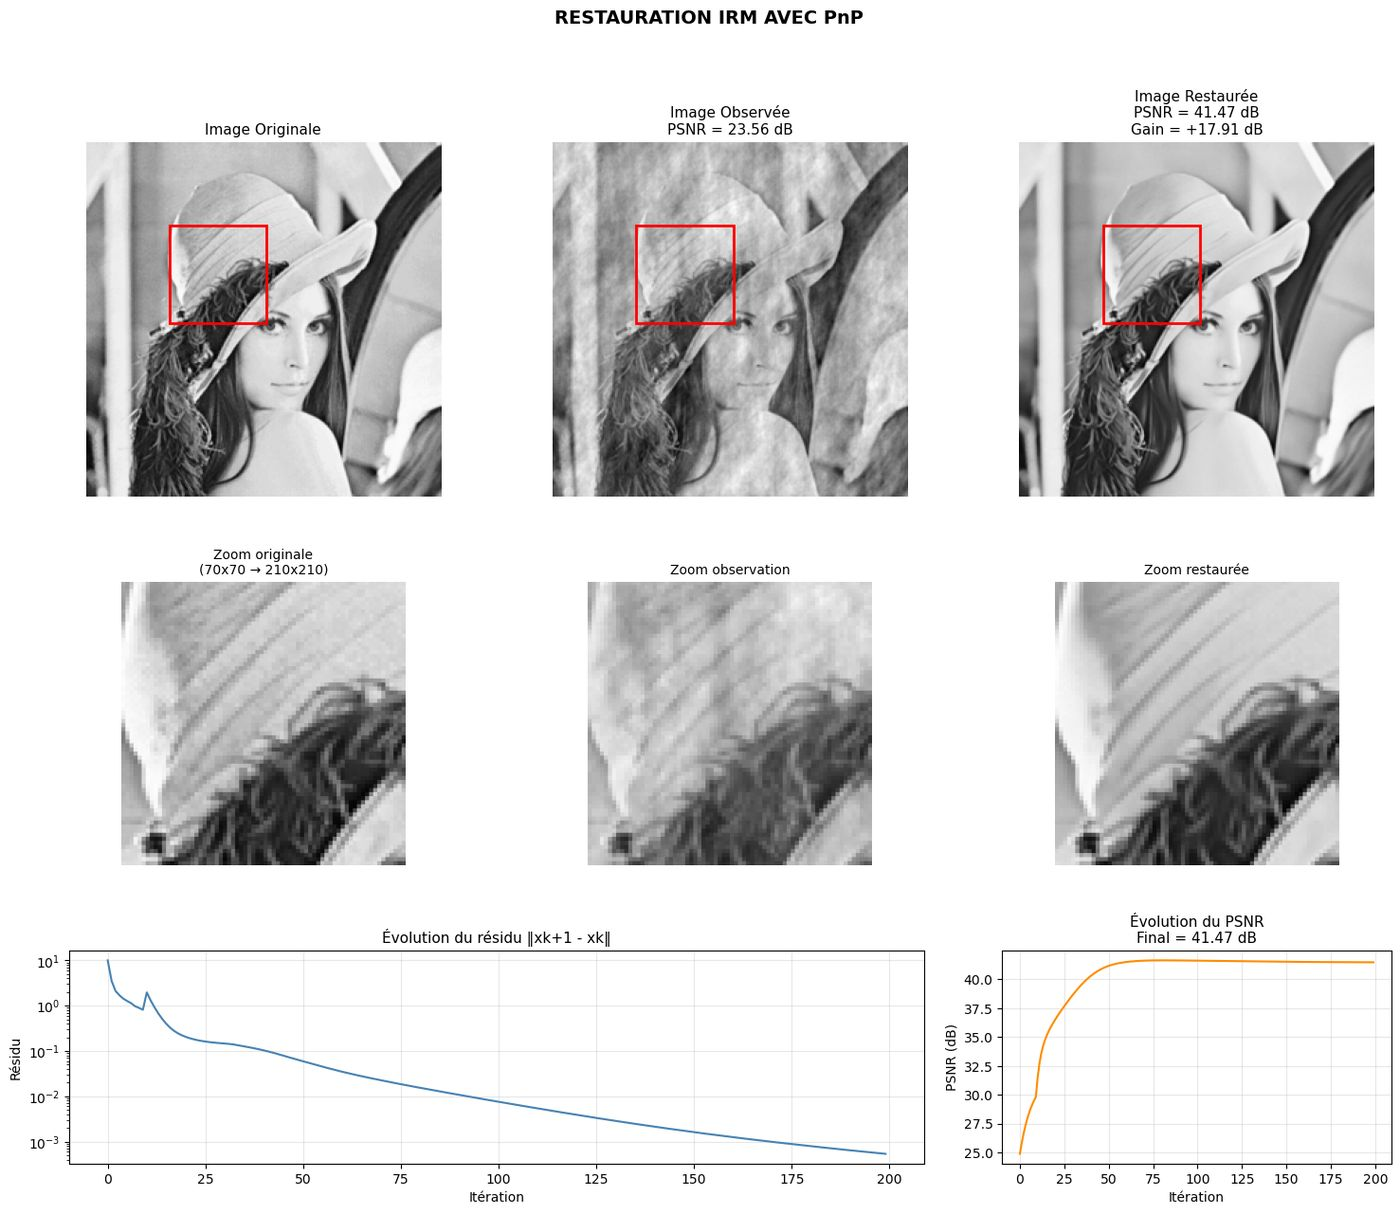


Test IRM sur : papillon2.png
Iter   0 | résidu = 12.347297 | sigma = 0.19608 | PSNR = 23.86 dB
Iter  20 | résidu = 0.235854 | sigma = 0.01961 | PSNR = 33.56 dB
Iter  40 | résidu = 0.128715 | sigma = 0.01961 | PSNR = 36.79 dB
Iter  60 | résidu = 0.067289 | sigma = 0.01961 | PSNR = 38.75 dB
Iter  80 | résidu = 0.030632 | sigma = 0.01961 | PSNR = 39.45 dB
Iter 100 | résidu = 0.016832 | sigma = 0.01961 | PSNR = 39.68 dB
Iter 120 | résidu = 0.011425 | sigma = 0.01961 | PSNR = 39.76 dB
Iter 140 | résidu = 0.009206 | sigma = 0.01961 | PSNR = 39.79 dB
Iter 160 | résidu = 0.008225 | sigma = 0.01961 | PSNR = 39.78 dB
Iter 180 | résidu = 0.007705 | sigma = 0.01961 | PSNR = 39.75 dB
Figure sauvegardée : mri_papillon2.png


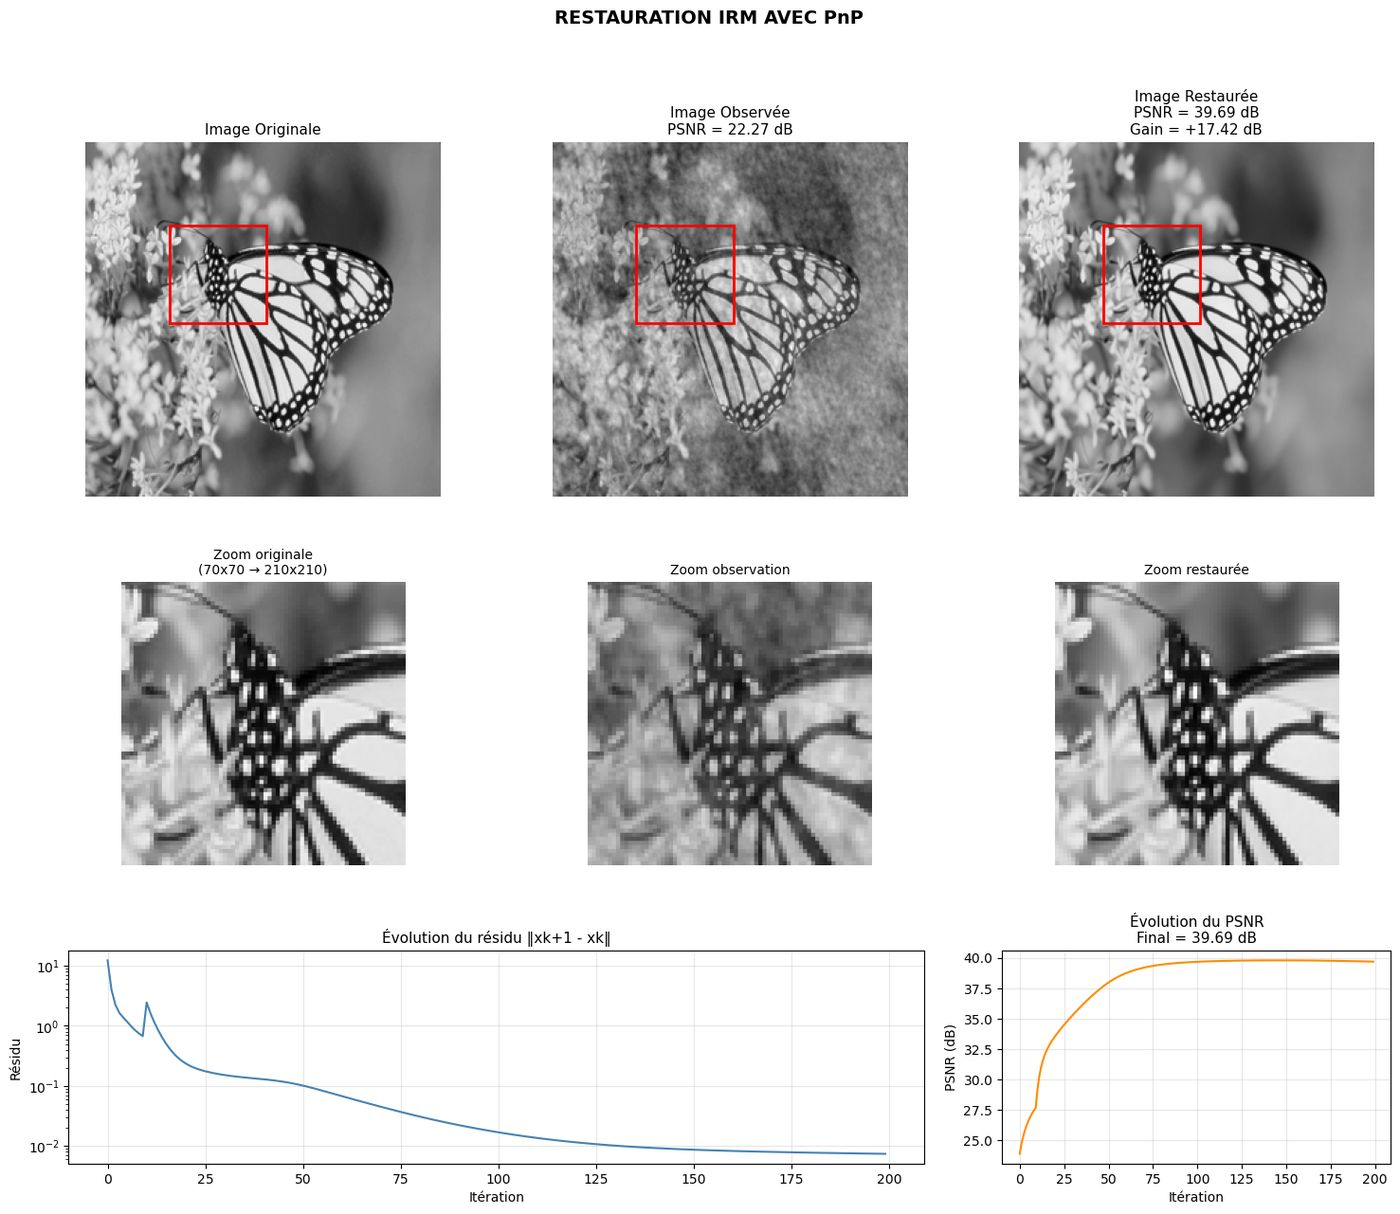


Test IRM sur : paysage.png
Iter   0 | résidu = 8.382415 | sigma = 0.19608 | PSNR = 26.16 dB
Iter  20 | résidu = 0.304613 | sigma = 0.01961 | PSNR = 34.90 dB
Iter  40 | résidu = 0.081887 | sigma = 0.01961 | PSNR = 36.16 dB
Iter  60 | résidu = 0.025092 | sigma = 0.01961 | PSNR = 36.19 dB
Iter  80 | résidu = 0.015347 | sigma = 0.01961 | PSNR = 36.03 dB
Iter 100 | résidu = 0.011257 | sigma = 0.01961 | PSNR = 35.86 dB
Iter 120 | résidu = 0.009064 | sigma = 0.01961 | PSNR = 35.71 dB
Iter 140 | résidu = 0.007774 | sigma = 0.01961 | PSNR = 35.56 dB
Iter 160 | résidu = 0.006921 | sigma = 0.01961 | PSNR = 35.43 dB
Iter 180 | résidu = 0.006288 | sigma = 0.01961 | PSNR = 35.30 dB
Figure sauvegardée : mri_paysage.png


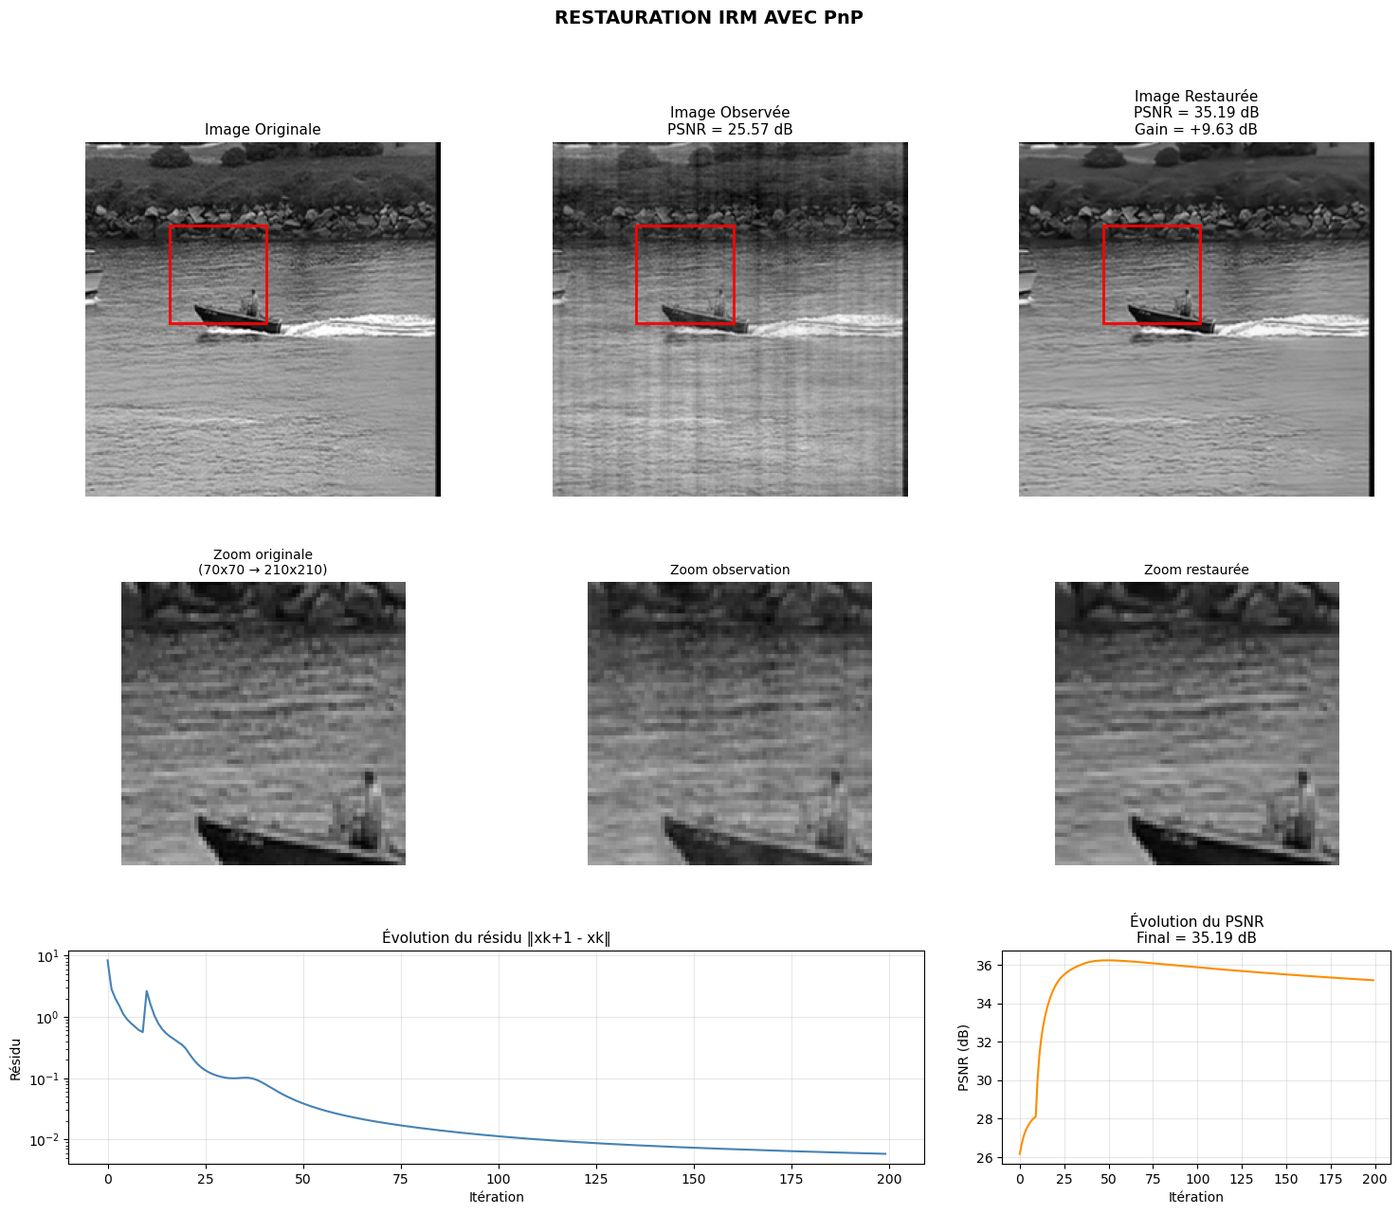

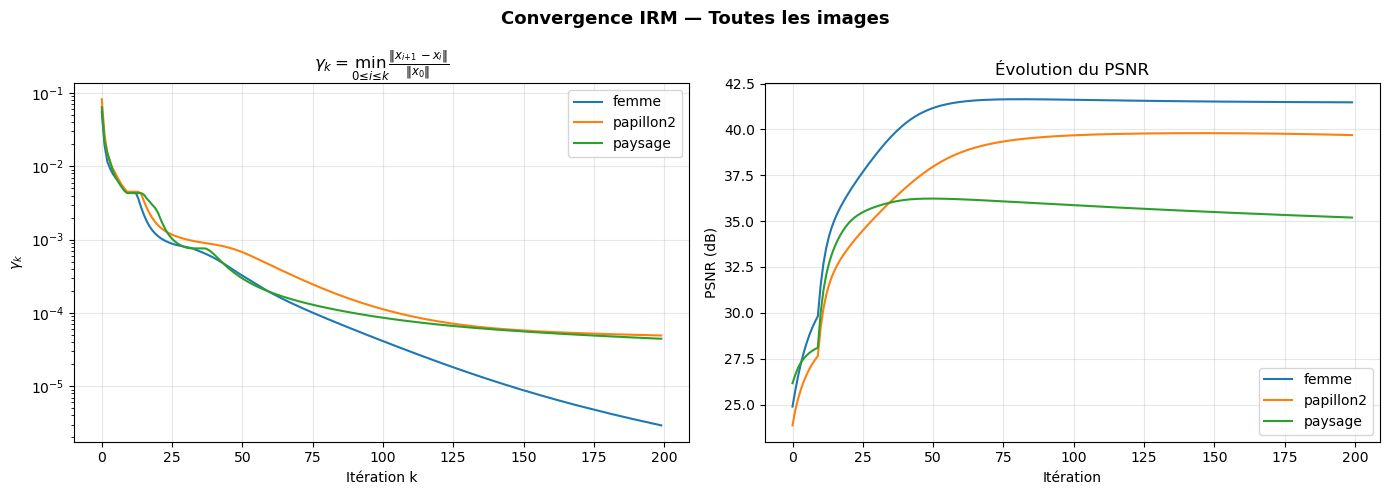

Courbes sauvegardées : courbes_convergence_mri.png


In [47]:
# =========================
# DÉFINITIONS (EN DEHORS DE LA BOUCLE)
# =========================
def psnr_mri(x_true, x_hat):
    mag_true = torch.sqrt(x_true[:, 0]**2 + x_true[:, 1]**2)
    mag_hat  = torch.sqrt(x_hat[:, 0]**2  + x_hat[:, 1]**2)
    mse = torch.mean((mag_true - mag_hat)**2)
    if mse == 0:
        return float('inf')
    return 10 * torch.log10(1.0 / mse)

def D_sigma(x, sigma):
    re = x[:, 0:1].repeat(1, 3, 1, 1)
    im = x[:, 1:2].repeat(1, 3, 1, 1)
    re_d = denoiser.forward(re, sigma)[:, 0:1]
    im_d = denoiser.forward(im, sigma)[:, 0:1]
    return torch.cat([re_d, im_d], dim=1)

def Prox_tau_f_mri(x, y, tau):
    return physics.prox_l2(x, y, 1/tau)

def PnP_MRI_with_history(y, K=200, sigma_main=5/255, sigma_warmup=50/255, n_warmup=10, tau=1.0, x_true=None):
    xk = physics.A_adjoint(y).detach()
    residual_history = []
    psnr_history = []

    for k in range(K):
        sigma_k = sigma_warmup if k < n_warmup else sigma_main

        with torch.no_grad():
            zk  = D_sigma(xk, sigma_k)
            xk1 = Prox_tau_f_mri(zk, y, tau)

        residual = torch.norm(xk1 - xk).item()
        residual_history.append(residual)

        if x_true is not None:
            current_psnr = psnr_mri(x_true, xk1).item()
            psnr_history.append(current_psnr)

        if k % 20 == 0:
            if x_true is not None:
                print(f"Iter {k:3d} | résidu = {residual:.6f} | sigma = {sigma_k:.5f} | PSNR = {current_psnr:.2f} dB")
            else:
                print(f"Iter {k:3d} | résidu = {residual:.6f} | sigma = {sigma_k:.5f}")

        xk = xk1.detach()

    return xk.detach(), residual_history, psnr_history

def show_mri_with_curves(x_true, y, x_restored, residual_history, psnr_history,
                          zoom_zone=(60, 60, 130, 130), fx=3.0, fy=3.0, save_path=None):
    x1, y1, x2, y2 = zoom_zone

    def mri_to_image(tensor):
        if tensor.dim() == 4:
            mag = torch.sqrt(tensor[0, 0]**2 + tensor[0, 1]**2)
        else:
            mag = torch.sqrt(tensor[0]**2 + tensor[1]**2)
        img = mag.cpu().detach().numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        img = (img * 255).astype(np.uint8)
        return cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    img_true        = mri_to_image(x_true)
    observation     = physics.A_adjoint(y).detach()
    img_observation = mri_to_image(observation)
    img_restored    = mri_to_image(x_restored)

    zone_true        = img_true[y1:y2, x1:x2]
    zone_observation = img_observation[y1:y2, x1:x2]
    zone_restored    = img_restored[y1:y2, x1:x2]

    zoom_true        = cv2.resize(zone_true,        None, fx=fx, fy=fy, interpolation=cv2.INTER_NEAREST)
    zoom_observation = cv2.resize(zone_observation, None, fx=fx, fy=fy, interpolation=cv2.INTER_NEAREST)
    zoom_restored    = cv2.resize(zone_restored,    None, fx=fx, fy=fy, interpolation=cv2.INTER_NEAREST)

    psnr_obs  = psnr_mri(x_true, observation).item()
    psnr_rest = psnr_mri(x_true, x_restored).item()
    final_psnr = psnr_history[-1] if psnr_history else psnr_rest

    img_true_rgb        = cv2.cvtColor(img_true,        cv2.COLOR_BGR2RGB)
    img_observation_rgb = cv2.cvtColor(img_observation, cv2.COLOR_BGR2RGB)
    img_restored_rgb    = cv2.cvtColor(img_restored,    cv2.COLOR_BGR2RGB)
    zoom_true_rgb        = cv2.cvtColor(zoom_true,        cv2.COLOR_BGR2RGB)
    zoom_observation_rgb = cv2.cvtColor(zoom_observation, cv2.COLOR_BGR2RGB)
    zoom_restored_rgb    = cv2.cvtColor(zoom_restored,    cv2.COLOR_BGR2RGB)

    fig = plt.figure(figsize=(18, 14))
    gs  = fig.add_gridspec(3, 3, height_ratios=[1, 0.8, 0.6], hspace=0.3, wspace=0.2)

    titles_row1 = [
        "Image Originale",
        f"Image Observée\nPSNR = {psnr_obs:.2f} dB",
        f"Image Restaurée\nPSNR = {psnr_rest:.2f} dB\nGain = +{psnr_rest - psnr_obs:.2f} dB"
    ]
    for i, (img, title) in enumerate(zip([img_true_rgb, img_observation_rgb, img_restored_rgb], titles_row1)):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(img, cmap='gray')
        ax.set_title(title, fontsize=11)
        ax.axis('off')
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)

    titles_row2 = [
        f"Zoom originale\n({zone_true.shape[1]}x{zone_true.shape[0]} → {zoom_true.shape[1]}x{zoom_true.shape[0]})",
        "Zoom observation",
        "Zoom restaurée"
    ]
    for i, (img, title) in enumerate(zip([zoom_true_rgb, zoom_observation_rgb, zoom_restored_rgb], titles_row2)):
        ax = fig.add_subplot(gs[1, i])
        ax.imshow(img, cmap='gray')
        ax.set_title(title, fontsize=10)
        ax.axis('off')

    ax_res = fig.add_subplot(gs[2, 0:2])
    ax_res.plot(residual_history, color='steelblue', linewidth=1.5)
    ax_res.set_title("Évolution du résidu ‖xk+1 - xk‖", fontsize=11)
    ax_res.set_xlabel("Itération")
    ax_res.set_ylabel("Résidu")
    ax_res.set_yscale("log")
    ax_res.grid(True, alpha=0.3)

    ax_psnr = fig.add_subplot(gs[2, 2])
    ax_psnr.plot(psnr_history, color='darkorange', linewidth=1.5)
    ax_psnr.set_title(f"Évolution du PSNR\nFinal = {final_psnr:.2f} dB", fontsize=11)
    ax_psnr.set_xlabel("Itération")
    ax_psnr.set_ylabel("PSNR (dB)")
    ax_psnr.grid(True, alpha=0.3)

    plt.suptitle("RESTAURATION IRM AVEC PnP", fontsize=14, fontweight='bold')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Figure sauvegardée : {save_path}")
    plt.show()

# =========================
# LISTE DES IMAGES À TESTER
# =========================
images_mri = [
    "femme.png",
    "papillon2.png",
    "paysage.png",
]

# =========================
# STOCKAGE DES RÉSULTATS
# =========================
all_residuals_mri = {}
all_psnrs_mri     = {}
all_x0_norms_mri  = {}

target_size = 256

for img_path in images_mri:
    print(f"\n{'='*60}")
    print(f"Test IRM sur : {img_path}")
    print(f"{'='*60}")

    # ── Chargement ──
    arr = np.array(Image.open(img_path).resize((target_size, target_size)))
    arr_gray = arr[:, :, 0].astype(np.float32) / 255.0  # canal R normalisé
    real_part = torch.tensor(arr_gray).to(device)
    imag_part = torch.zeros_like(real_part)
    x_true = torch.stack([real_part, imag_part], dim=0).unsqueeze(0).to(device)
    # x_true : (1, 2, 256, 256)

    # ── Masque & Physics ──
    torch.manual_seed(42)
    mask = torch.bernoulli(0.7 * torch.ones(target_size, target_size)).to(device)
    physics = dinv.physics.MRI(mask=mask, img_size=(target_size, target_size), device=device)

    # ── Dégradation ──
    y = physics(x_true)

    # ── Restauration ──
    x_restored, residual_history, psnr_history = PnP_MRI_with_history(
        y=y, K=200,
        sigma_main=5/255, sigma_warmup=50/255, n_warmup=10, tau=1.0,
        x_true=x_true
    )

    # ── Stockage ──
    img_name = img_path.replace('.png', '')
    all_residuals_mri[img_name] = residual_history
    all_psnrs_mri[img_name]     = psnr_history
    all_x0_norms_mri[img_name]  = torch.norm(y).item()

    # ── Affichage individuel ──
    show_mri_with_curves(
        x_true, y, x_restored, residual_history, psnr_history,
        zoom_zone=(60, 60, 130, 130), fx=3.0, fy=3.0,
        save_path=f"mri_{img_name}.png"
    )

# =========================
# COURBES COMPARAISON (UNE SEULE FOIS)
# =========================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for img_name in all_residuals_mri:
    residuals = all_residuals_mri[img_name]
    x0_norm   = all_x0_norms_mri[img_name]

    # Résidu normalisé : gamma_k = min_{0<=i<=k} ||x_{i+1} - x_i|| / ||x_0||
    normalized  = []
    current_min = float('inf')
    for r in residuals:
        current_min = min(current_min, r / (x0_norm + 1e-8))
        normalized.append(current_min)

    axes[0].plot(normalized, linewidth=1.5, label=img_name)
    axes[1].plot(all_psnrs_mri[img_name], linewidth=1.5, label=img_name)

axes[0].set_title(r"$\gamma_k = \min_{0 \leq i \leq k} \frac{\|x_{i+1} - x_i\|}{\|x_0\|}$", fontsize=12)
axes[0].set_xlabel("Itération k")
axes[0].set_ylabel(r"$\gamma_k$")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("Évolution du PSNR", fontsize=12)
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("PSNR (dB)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle("Convergence IRM — Toutes les images", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("courbes_convergence_mri.png", dpi=150, bbox_inches='tight')
plt.show()
print("Courbes sauvegardées : courbes_convergence_mri.png")


Test IRM sur : femme.png
Iter   0 | résidu = 10.059044 | sigma = 0.19608 | PSNR = 24.89 dB
Iter  20 | résidu = 0.204599 | sigma = 0.01961 | PSNR = 36.55 dB
Iter  40 | résidu = 0.102818 | sigma = 0.01961 | PSNR = 40.31 dB
Iter  60 | résidu = 0.034766 | sigma = 0.01961 | PSNR = 41.50 dB
Iter  80 | résidu = 0.015332 | sigma = 0.01961 | PSNR = 41.64 dB
Iter 100 | résidu = 0.007557 | sigma = 0.01961 | PSNR = 41.61 dB
Iter 120 | résidu = 0.003890 | sigma = 0.01961 | PSNR = 41.57 dB
Iter 140 | résidu = 0.002123 | sigma = 0.01961 | PSNR = 41.53 dB
Iter 160 | résidu = 0.001248 | sigma = 0.01961 | PSNR = 41.50 dB
Iter 180 | résidu = 0.000788 | sigma = 0.01961 | PSNR = 41.49 dB

Test IRM sur : papillon2.png
Iter   0 | résidu = 12.347297 | sigma = 0.19608 | PSNR = 23.86 dB
Iter  20 | résidu = 0.235854 | sigma = 0.01961 | PSNR = 33.56 dB
Iter  40 | résidu = 0.128715 | sigma = 0.01961 | PSNR = 36.79 dB
Iter  60 | résidu = 0.067289 | sigma = 0.01961 | PSNR = 38.75 dB
Iter  80 | résidu = 0.030632 | s

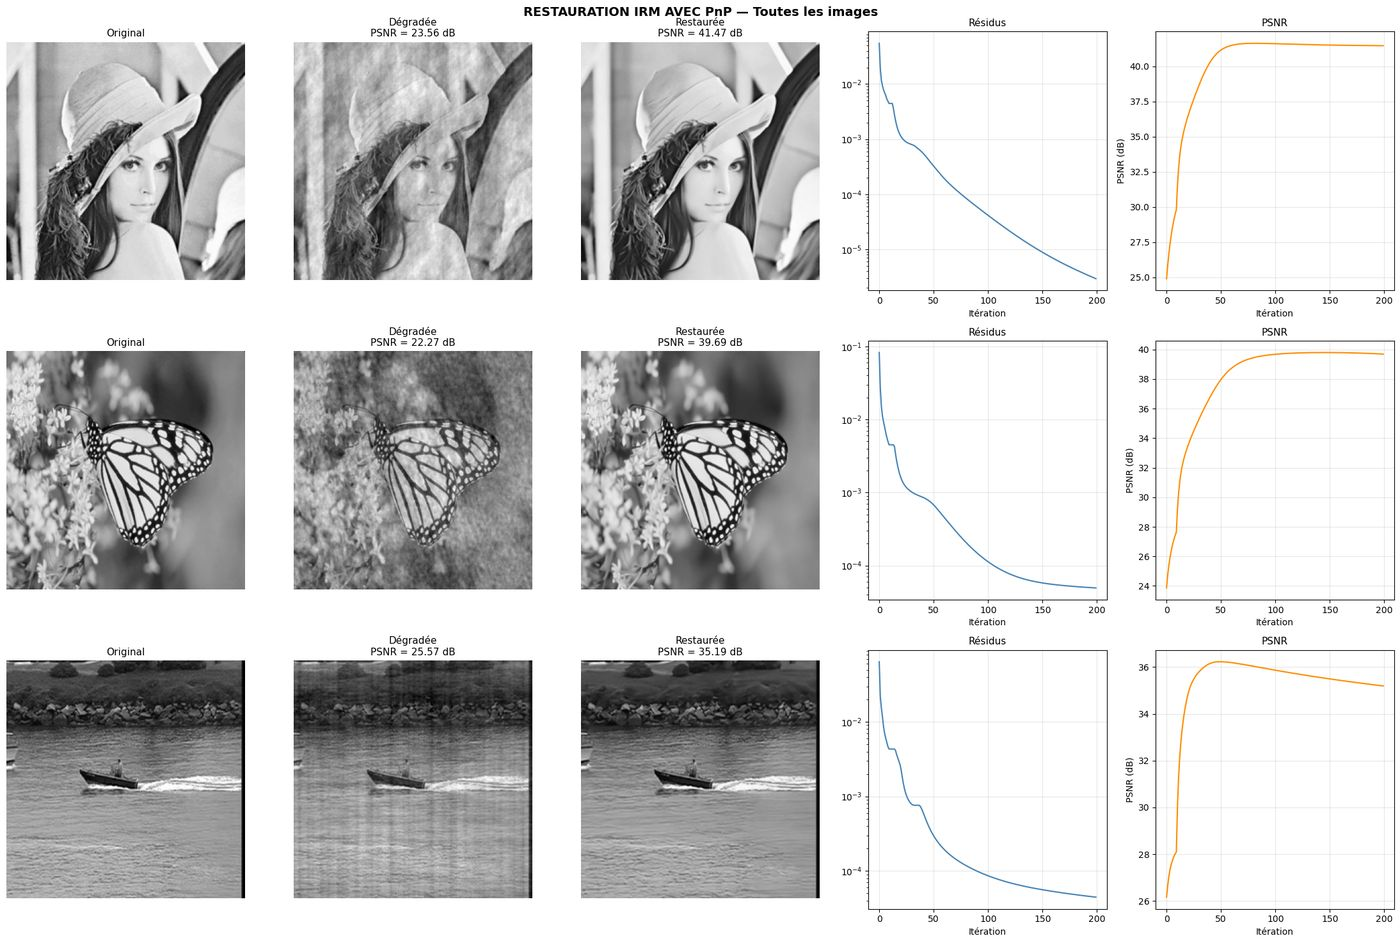

Sauvegardé : mri_all_images.png


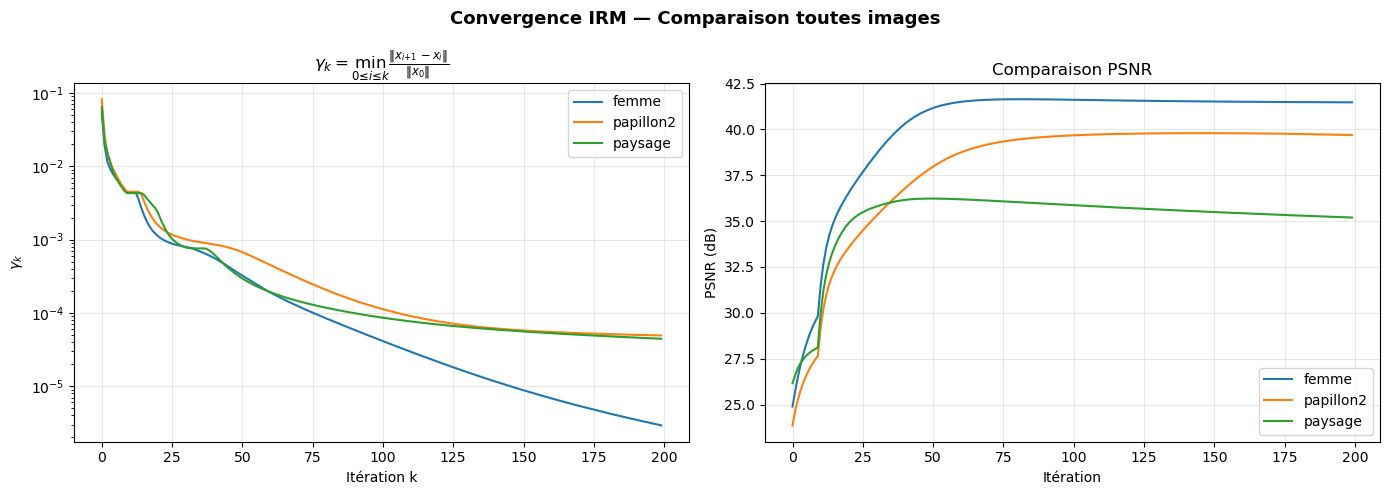

Sauvegardé : courbes_comparaison_mri.png


In [48]:
def show_all_mri_results(all_residuals_mri, all_psnrs_mri, all_x0_norms_mri, all_images_mri):
    """
    Affiche pour chaque image : originale, observée, restaurée + courbes résidu/PSNR
    Puis une figure de comparaison des courbes normalisées en bas
    """

    # =========================
    # FIGURE 1 : UNE LIGNE PAR IMAGE
    # =========================
    n_images = len(all_images_mri)
    fig, axes = plt.subplots(n_images, 5, figsize=(22, 5 * n_images))

    def mri_to_img(tensor):
        if tensor.dim() == 4:
            mag = torch.sqrt(tensor[0, 0]**2 + tensor[0, 1]**2)
        else:
            mag = torch.sqrt(tensor[0]**2 + tensor[1]**2)
        img = mag.cpu().detach().numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        return img

    def psnr_local(x_true, x_hat):
        mag_true = torch.sqrt(x_true[:, 0]**2 + x_true[:, 1]**2)
        mag_hat  = torch.sqrt(x_hat[:, 0]**2  + x_hat[:, 1]**2)
        mse = torch.mean((mag_true - mag_hat)**2)
        if mse == 0:
            return float('inf')
        return 10 * torch.log10(1.0 / mse)

    for row, (img_name, imgs) in enumerate(all_images_mri.items()):
        x_true     = imgs['x_true'].to(device)
        y          = imgs['y'].to(device)
        x_restored = imgs['x_restored'].to(device)

        # Physics pour l'observation
        observation = physics.A_adjoint(y).detach()

        psnr_obs  = psnr_local(x_true, observation).item()
        psnr_rest = psnr_local(x_true, x_restored).item()

        img_true_disp  = mri_to_img(x_true)
        img_obs_disp   = mri_to_img(observation)
        img_rest_disp  = mri_to_img(x_restored)

        residuals  = all_residuals_mri[img_name]
        psnr_hist  = all_psnrs_mri[img_name]

        # Résidu normalisé
        x0_norm = all_x0_norms_mri[img_name]
        normalized  = []
        current_min = float('inf')
        for r in residuals:
            current_min = min(current_min, r / (x0_norm + 1e-8))
            normalized.append(current_min)

        ax = axes[row] if n_images > 1 else axes

        # Col 0 : Originale
        ax[0].imshow(img_true_disp, cmap='gray')
        ax[0].set_title("Original", fontsize=11)
        ax[0].axis('off')

        # Col 1 : Observée
        ax[1].imshow(img_obs_disp, cmap='gray')
        ax[1].set_title(f"Dégradée\nPSNR = {psnr_obs:.2f} dB", fontsize=11)
        ax[1].axis('off')

        # Col 2 : Restaurée
        ax[2].imshow(img_rest_disp, cmap='gray')
        ax[2].set_title(f"Restaurée\nPSNR = {psnr_rest:.2f} dB", fontsize=11)
        ax[2].axis('off')

        # Col 3 : Résidus normalisés
        ax[3].plot(normalized, color='steelblue', linewidth=1.5)
        ax[3].set_title("Résidus", fontsize=11)
        ax[3].set_xlabel("Itération")
        ax[3].set_yscale("log")
        ax[3].grid(True, alpha=0.3)

        # Col 4 : PSNR
        ax[4].plot(psnr_hist, color='darkorange', linewidth=1.5)
        ax[4].set_title("PSNR", fontsize=11)
        ax[4].set_xlabel("Itération")
        ax[4].set_ylabel("PSNR (dB)")
        ax[4].grid(True, alpha=0.3)

    plt.suptitle("RESTAURATION IRM AVEC PnP — Toutes les images", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("mri_all_images.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Sauvegardé : mri_all_images.png")

    # =========================
    # FIGURE 2 : COURBES DE COMPARAISON
    # =========================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for img_name in all_residuals_mri:
        residuals = all_residuals_mri[img_name]
        x0_norm   = all_x0_norms_mri[img_name]

        normalized  = []
        current_min = float('inf')
        for r in residuals:
            current_min = min(current_min, r / (x0_norm + 1e-8))
            normalized.append(current_min)

        axes[0].plot(normalized, linewidth=1.5, label=img_name)
        axes[1].plot(all_psnrs_mri[img_name], linewidth=1.5, label=img_name)

    axes[0].set_title(r"$\gamma_k = \min_{0 \leq i \leq k} \frac{\|x_{i+1} - x_i\|}{\|x_0\|}$", fontsize=12)
    axes[0].set_xlabel("Itération k")
    axes[0].set_ylabel(r"$\gamma_k$")
    axes[0].set_yscale("log")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].set_title("Comparaison PSNR", fontsize=12)
    axes[1].set_xlabel("Itération")
    axes[1].set_ylabel("PSNR (dB)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.suptitle("Convergence IRM — Comparaison toutes images", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig("courbes_comparaison_mri.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Sauvegardé : courbes_comparaison_mri.png")


# =========================
# BOUCLE + STOCKAGE
# =========================
all_residuals_mri = {}
all_psnrs_mri     = {}
all_x0_norms_mri  = {}
all_images_mri    = {}

target_size = 256

for img_path in images_mri:
    print(f"\n{'='*60}")
    print(f"Test IRM sur : {img_path}")
    print(f"{'='*60}")

    arr      = np.array(Image.open(img_path).resize((target_size, target_size)))
    arr_gray = arr[:, :, 0].astype(np.float32) / 255.0
    real_part = torch.tensor(arr_gray).to(device)
    imag_part = torch.zeros_like(real_part)
    x_true = torch.stack([real_part, imag_part], dim=0).unsqueeze(0).to(device)

    torch.manual_seed(42)
    mask    = torch.bernoulli(0.7 * torch.ones(target_size, target_size)).to(device)
    physics = dinv.physics.MRI(mask=mask, img_size=(target_size, target_size), device=device)

    y = physics(x_true)

    x_restored, residual_history, psnr_history = PnP_MRI_with_history(
        y=y, K=200,
        sigma_main=5/255, sigma_warmup=50/255, n_warmup=10, tau=1.0,
        x_true=x_true
    )

    img_name = img_path.replace('.png', '')
    all_residuals_mri[img_name] = residual_history
    all_psnrs_mri[img_name]     = psnr_history
    all_x0_norms_mri[img_name]  = torch.norm(y).item()
    all_images_mri[img_name]    = {
        'x_true':     x_true.cpu(),
        'y':          y.cpu(),
        'x_restored': x_restored.cpu()
    }

# =========================
# AFFICHAGE FINAL
# =========================
show_all_mri_results(all_residuals_mri, all_psnrs_mri, all_x0_norms_mri, all_images_mri)